# Comprehensive evaluation of three chord-refinement Transformers

**Research:** Context-Aware Chord Refinement for Genre-Aware Melody Harmonization.

This independent notebook loads the saved baseline, class-weighted and multi-task best checkpoints. It evaluates the unchanged v6 test split, compares exact labels and candidate rankings, separates full-chord versus quality-only recognition, diagnoses errors, examines recorded training behavior, measures inference efficiency and reports explicit musical proxies and track-bootstrap uncertainty.

**No retraining, preprocessing rebuild, vocabulary fitting, checkpoint changes or auxiliary re-ranking occurs.** Every run writes only to a new evaluation directory. Initial output is `outputs/comprehensive_model_evaluation/{figures,tables}`; later runs use a timestamped child under `runs/` to preserve previous results.

## 1. Evaluation overview

One token is one beat in a variable-length, up-to-four-bar sequence. Detailed targets preserve root, extension and represented inversion. Raw logits over the entire saved target vocabulary determine candidates; PAD/UNK outputs are not filtered or renormalized. Legitimate no-chord N remains supervised. Only `target_loss_mask & beat_attention_mask`, with valid non-reserved target IDs, enters objective metrics.

All models receive the same 17 input tensors, same ordered test sequences, same valid targets, batch size, CPU threads and device. The auxiliary head is evaluated separately and never used to change full-chord predictions. Rankings use stable descending logits with saved vocabulary ID as the exact-tie rule.

### Reproducible settings

The default is CPU, batch size 32, four CPU threads, seed 42, 2,000 paired track-bootstrap replicates and 95% confidence. Benchmarks warm up five batches and repeat the complete test pass three times. CPU forward timing excludes loading, transfers, loss and candidate extraction. CUDA can be selected only when a compatible installation is available; worker timing synchronizes CUDA when used.

In [1]:
from pathlib import Path
from datetime import datetime,timezone,timedelta
import sys,json,math
import numpy as np
import pandas as pd
import torch
from IPython.display import display,Markdown,Image
cwd=Path.cwd().resolve()
ROOT=next((p for p in [cwd,*cwd.parents,cwd/'vocal-harmonization'] if (p/'experiments/rahul/src/comprehensive_evaluation.py').exists()),None)
if ROOT is None:raise FileNotFoundError('Run inside the vocal-harmonization repository with its project .venv kernel.')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from experiments.rahul.src.comprehensive_evaluation import (
    EvaluationStudy,discover_runs,evaluate,error_analysis,training_behavior,musical_diagnostics,
    track_bootstrap,select_examples,benchmark,make_figures,finalize,read_json,save_json,save_table,
    scores,confusion,MODELS,DISPLAY,COLORS,INPUT_KEYS)
DEVICE='cpu';BATCH_SIZE=32;THREADS=4;SEED=42
BOOTSTRAP_REPETITIONS=2000;CONFIDENCE=.95;BENCHMARK_REPETITIONS=3;WARMUP_BATCHES=5
BASE=ROOT/'experiments/rahul'
DATASET=BASE/'outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
OUTPUT_BASE=BASE/'outputs/comprehensive_model_evaluation'
stamp=datetime.now(timezone(timedelta(hours=5,minutes=30))).strftime('%Y%m%d_%H%M%S_%f')
OUT=OUTPUT_BASE if not OUTPUT_BASE.exists() else OUTPUT_BASE/'runs'/('evaluation_'+stamp)
RUNS=discover_runs(ROOT) # Fails if ambiguous; supply explicit runs instead of silently choosing.
pd.set_option('display.max_columns',30);pd.set_option('display.max_colwidth',90)
print('Output:',OUT.relative_to(ROOT),'\nDevice:',DEVICE,'Batch size:',BATCH_SIZE,'Threads:',THREADS)
print('No fitting or training code is called.')

Output: experiments\rahul\outputs\comprehensive_model_evaluation 
Device: cpu Batch size: 32 Threads: 4
No fitting or training code is called.


## 2. Loaded model and dataset verification

### Existing implementation reviewed

Notebooks 05?09 were inspected: architecture smoke test, baseline training, weighted training, maj7 diagnostics and multi-task training. Models are loaded with `src/model/checkpoint.py` and `src/model/multitask_transformer.py`; shared encoders, explicit attention blocks and model settings remain in `src/model/`. The saved dataset loader, group-split validator, masking/metrics utilities and chord parser are reused.

The baseline and weighted models have the same architecture; weighting changes the training loss. The multi-task model adds a linear quality head to the shared contextual representation. Its quality mapping is validated against the saved vocabulary. Model dimensions, parameter counts, quality count, checkpoint locations and class hashes below come from actual files, not assumed constants.

Setup verifies each checkpoint's complete DatasetSpec and target vocabulary identity, compatible input/model configurations, split-group isolation, existing readiness hashes and target/event alignment. It snapshots existing notebooks, code and old experiment outputs for a final preservation check. Test arrays are cached once in memory to avoid repeated NPZ decompression; no full probability cube is retained.

In [2]:
study=EvaluationStudy(ROOT,OUT,dataset=DATASET,runs=RUNS,batch_size=BATCH_SIZE,device=DEVICE,threads=THREADS,seed=SEED)
configuration=read_json(study.tables/'evaluation_configuration.json')
display(pd.DataFrame(configuration))
print('Saved target labels:',study.C,'coordinates; prefix:',study.labels[:3])
print('Vocabulary qualities:',study.qualities)
print('Dataset:',study.relative(DATASET),'\nEvent identity SHA256:',study.identity_hash)
print('First aligned test events:')
display(pd.DataFrame(study.events[:3])[['track_id','sequence_id','position_in_sequence','beat_index','bar_number','beat_position','basic_chord','reference_chord']])
assert len(study.y)==read_json(DATASET/'preprocessing_statistics.json')['test']['valid_targets']
assert all(study.models[n].spec==study.spec for n in MODELS)
# Source inventory is read as evidence, never executed from the old notebooks.
notebook_inventory=[]
for prefix in ('05','06','07','08','09'):
    path=next((BASE/'notebooks').glob(prefix+'*.ipynb'))
    notebook=json.loads(path.read_text(encoding='utf-8'))
    notebook_inventory.append({'notebook':path.name,'code_cells':sum(c['cell_type']=='code' for c in notebook['cells']),
        'checkpoint_usage':'Training experiment' if prefix in ('06','07','09') else 'Architecture/diagnostic inspection'})
display(save_table(study.tables,'reviewed_notebooks',notebook_inventory))

,model,checkpoint,checkpoint_sha256,dataset,device,batch_size,threads,sequences,valid_targets,test_tracks,classes,d_model,layers,parameters,trainable_parameters,quality_categories,checkpoint_bytes,target_vocabulary_sha256,event_identity_sha256
0,baseline,experiments/rahul/outputs/transformer_training/notebook_full_inputs_20261019_194104_12...,3c2c166d7de783bcf5e1bb3af1c48345012d02d2556022e80c72c126cba2b1ca,experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar,cpu,32,4,990,14077,32,402,128,2,349074,349074,NaN,1425714,b940cdd809e654f30508f8e1c354e194c1bef02951353e21ee21db7788e54904,05bfbeeb1be94daee05cf4ee4c3b43e6e97372e2e2dff7024dbdeb6c9fb08cf9
1,weighted,experiments/rahul/outputs/weighted_transformer/weighted_20261020_003318_832489/best_we...,fb1bd7c53c8181408419c1f6141c8803528af2b33b2f798600f2efd79d0a2ff5,experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar,cpu,32,4,990,14077,32,402,128,2,349074,349074,NaN,1426875,b940cdd809e654f30508f8e1c354e194c1bef02951353e21ee21db7788e54904,05bfbeeb1be94daee05cf4ee4c3b43e6e97372e2e2dff7024dbdeb6c9fb08cf9
2,multitask,experiments/rahul/outputs/multitask_transformer/multitask_20261020_164527_051309/best_...,2477a26cc09e6fe71d264189221c0cf24722770a26aefbb20a37065e0efc63da,experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar,cpu,32,4,990,14077,32,402,128,2,350751,350751,13.0,1438929,b940cdd809e654f30508f8e1c354e194c1bef02951353e21ee21db7788e54904,05bfbeeb1be94daee05cf4ee4c3b43e6e97372e2e2dff7024dbdeb6c9fb08cf9


Saved target labels: 402 coordinates; prefix: ('PAD', 'UNK', 'N')
Vocabulary qualities: ['7', '9', 'N', 'aug', 'dim', 'dim7', 'hdim7', 'maj', 'maj7', 'min', 'min7', 'min9', 'sus4']
Dataset: experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar 
Event identity SHA256: 05bfbeeb1be94daee05cf4ee4c3b43e6e97372e2e2dff7024dbdeb6c9fb08cf9
First aligned test events:


,track_id,sequence_id,position_in_sequence,beat_index,bar_number,beat_position,basic_chord,reference_chord
0,156887,0,0,0,0,1,N,N
1,156887,0,1,1,0,2,N,N
2,156887,0,2,2,1,1,Am,A:min


,notebook,code_cells,checkpoint_usage
0,05_transformer_architecture.ipynb,14,Architecture/diagnostic inspection
1,06_train_transformer.ipynb,17,Training experiment
2,07_train_transformer_weighted.ipynb,15,Training experiment
3,08_maj7_failure_analysis.ipynb,11,Architecture/diagnostic inspection
4,09_train_transformer_multitask.ipynb,16,Training experiment


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


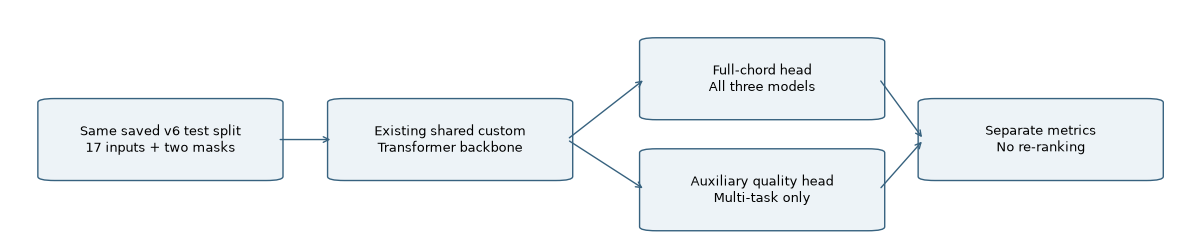

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(12,2.6));ax.set_axis_off()
boxes=[('Same saved v6 test split\n17 inputs + two masks',.01,.20),('Existing shared custom\nTransformer backbone',.27,.20),('Full-chord head\nAll three models',.55,.43),('Auxiliary quality head\nMulti-task only',.55,.01),('Separate metrics\nNo re-ranking',.80,.20)]
for label,x,y in boxes:
    ax.add_patch(FancyBboxPatch((x,y),.19,.28,boxstyle='round,pad=0.015',facecolor='#EDF3F7',edgecolor='#37627F'))
    ax.text(x+.095,y+.14,label,ha='center',va='center',fontsize=9)
for start,end in [((.21,.34),(.26,.34)),((.47,.34),(.54,.57)),((.47,.34),(.54,.15)),((.75,.57),(.79,.34)),((.75,.15),(.79,.34))]:
    ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#37627F'})
ax.set(xlim=(-.03,1.02),ylim=(-.04,.83));fig.tight_layout()
fig.savefig(study.figures/'evaluation_flow.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)

## 3. Overall classification performance

Exact accuracy requires the complete saved label, including root, detailed quality and represented inversion. Macro precision/recall/F1 average only classes with positive reference support in this evaluated population, excluding PAD/UNK and retaining N. Undefined precision contributes zero in averages; detailed tables display undefined values as unavailable. Weighted averages use reference support. For this single-label task, micro F1 equals exact accuracy.

All models use the same unweighted masked full-chord CE in nats. The multi-task training loss is not substituted for its test chord CE. Every class, including zero-support classes, remains in per-class tables. Fresh values are checked against saved run metrics when available, and against an independent scikit-learn calculation.

In [4]:
overall=evaluate(study)
from sklearn.metrics import precision_recall_fscore_support,accuracy_score
supported=np.flatnonzero(np.bincount(study.y,minlength=study.C)>0)
for name in MODELS:
    p=study.predictions[name]['predicted_ids'];m=study.results[name]['metrics']
    assert math.isclose(accuracy_score(study.y,p),m['accuracy'],abs_tol=1e-12)
    for average in ('macro','weighted'):
        precision,recall,f1,_=precision_recall_fscore_support(study.y,p,labels=supported,average=average,zero_division=0)
        for key,value in [('precision',precision),('recall',recall),('f1',f1)]:assert math.isclose(m[average+'_'+key],value,abs_tol=1e-12)
display(overall[['model','valid_targets','accuracy','macro_precision','macro_recall','macro_f1','weighted_precision','weighted_recall','weighted_f1','micro_f1','cross_entropy']])
winners=[]
for metric in ('accuracy','macro_f1','weighted_f1','micro_f1','cross_entropy'):
    best=overall[metric].min() if metric=='cross_entropy' else overall[metric].max()
    winners.append({'metric':metric,'best_models':overall.loc[np.isclose(overall[metric],best,rtol=0,atol=1e-12),'model'].tolist(),'best_value':float(best)})
display(save_table(study.tables,'classification_winners',winners))
b=study.results['baseline']['metrics'];m=study.results['multitask']['metrics']
display(Markdown(f'Multi-task minus baseline: **{100*(m["accuracy"]-b["accuracy"]):+.3f} percentage points** exact accuracy and **{m["macro_f1"]-b["macro_f1"]:+.4f}** macro F1. These are numerical differences; paired uncertainty is evaluated in section 10.'))

baseline: 14,077 paired targets; exact=79.505576%; macro F1=0.325978


weighted: 14,077 paired targets; exact=78.496839%; macro F1=0.319876


multitask: 14,077 paired targets; exact=80.379342%; macro F1=0.328914


,model,valid_targets,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,micro_f1,cross_entropy
0,baseline,14077,0.795056,0.313338,0.353829,0.325978,0.709120,0.795056,0.734995,0.795056,0.855225
1,weighted,14077,0.784968,0.318497,0.351780,0.319876,0.719661,0.784968,0.736672,0.784968,0.924474
2,multitask,14077,0.803793,0.325526,0.353681,0.328914,0.721289,0.803793,0.746456,0.803793,0.812550


,metric,best_models,best_value
0,accuracy,[multitask],0.803793
1,macro_f1,[multitask],0.328914
2,weighted_f1,[multitask],0.746456
3,micro_f1,[multitask],0.803793
4,cross_entropy,[multitask],0.812550


Multi-task minus baseline: **+0.874 percentage points** exact accuracy and **+0.0029** macro F1. These are numerical differences; paired uncertainty is evaluated in section 10.

## 4. Top-K candidate evaluation and actual examples

Top-K is exact-label membership, not quality-family matching. MRR averages `1 / true_class_rank` over every valid target; all full-vocabulary ranks are available. Mean reference probability uses raw softmax. Top-1-to-top-3 gain measures candidate-retrieval improvement, not automatic final-selection accuracy.

Example categories are fixed descriptive rules: all correct, multi-task correction, weighted correction on a minority full-chord class, maj7 failure, target in top-3 but not top-1, wrong root, wrong quality and rare failure. Minority full-chord classes have training support 1?99 beats. Rare-quality examples separately use aggregate quality training support 1?99 beats. Both rules are selected without test-performance tuning. The first actual event satisfying each rule is shown. Missing categories are explicitly counted; examples are illustrative, not frequency estimates.

In [5]:
display(overall[['model','top1_accuracy','top3_accuracy','top5_accuracy','mean_reciprocal_rank','mean_reference_probability','top1_to_top3_gain']])
examples=select_examples(study)
display(study.example_availability)
example_view=examples[['category','model','track_id','beat_index','beat_position','basic_chord','melody_pitch_classes','key','mode','roman','harmonic_function','genre','reference_chord','predicted_chord','top3','top5']].copy()
for key in ('top3','top5'):
    example_view[key]=example_view[key].map(lambda rows:'; '.join(f'{r["chord"]}: {r["probability"]:.2%}' for r in rows))
display(example_view)
display(Markdown('Candidate probabilities describe this classifier, not calibrated confidence in musical correctness. The raw tables retain full numerical precision; the display rounds percentages only.'))

,model,top1_accuracy,top3_accuracy,top5_accuracy,mean_reciprocal_rank,mean_reference_probability,top1_to_top3_gain
0,baseline,0.795056,0.941749,0.984869,0.874429,0.715753,0.146693
1,weighted,0.784968,0.924629,0.971514,0.862842,0.620679,0.139660
2,multitask,0.803793,0.940968,0.981033,0.879508,0.735372,0.137174


,category,matching_events,selection
0,All three exact correct,10797,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
1,Multi-task improves baseline,223,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
2,Weighted improves a minority class,11,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
3,Major-seventh failure,926,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
4,True target in top 3 but not top 1,1931,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
5,Wrong root,15,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
6,Correct root but wrong quality,2349,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
7,Rare-quality failure,8,"First qualifying saved test event; deterministic, illustrative, not representative of ..."
8,Rare full-chord-class failure,654,"First qualifying saved test event; deterministic, illustrative, not representative of ..."


,category,model,track_id,beat_index,beat_position,basic_chord,melody_pitch_classes,key,mode,roman,harmonic_function,genre,reference_chord,predicted_chord,top3,top5
0,All three exact correct,baseline,156887,0,1,N,[],F,major,N,unknown,[UNANNOTATED],N,N,N: 99.91%; E:min: 0.01%; E:min7: 0.00%,N: 99.91%; E:min: 0.01%; E:min7: 0.00%; D#:maj: 0.00%; F:7: 0.00%
1,All three exact correct,weighted,156887,0,1,N,[],F,major,N,unknown,[UNANNOTATED],N,N,N: 99.79%; G:sus4: 0.02%; D#:maj: 0.01%,N: 99.79%; G:sus4: 0.02%; D#:maj: 0.01%; E:maj/b2: 0.01%; B:hdim7: 0.01%
2,All three exact correct,multitask,156887,0,1,N,[],F,major,N,unknown,[UNANNOTATED],N,N,N: 99.86%; E:min: 0.01%; E:min7: 0.01%,N: 99.86%; E:min: 0.01%; E:min7: 0.01%; D#:maj: 0.00%; A:maj: 0.00%
3,Multi-task improves baseline,baseline,21982,340,2,F#,"[9, 9]",Db,minor,unknown,unknown,"[alternative, dance, lounge, pop, rock]",F#:maj,F#:maj/3,F#:maj/3: 49.69%; F#:maj: 40.65%; F#:maj7: 2.45%,F#:maj/3: 49.69%; F#:maj: 40.65%; F#:maj7: 2.45%; B:maj: 1.39%; F#:maj/5: 0.75%
4,Multi-task improves baseline,weighted,21982,340,2,F#,"[9, 9]",Db,minor,unknown,unknown,"[alternative, dance, lounge, pop, rock]",F#:maj,F#:maj,F#:maj: 46.19%; F#:maj/3: 36.86%; F#:maj/5: 9.94%,F#:maj: 46.19%; F#:maj/3: 36.86%; F#:maj/5: 9.94%; F#:maj/6: 1.33%; F#:maj/b7: 0.50%
5,Multi-task improves baseline,multitask,21982,340,2,F#,"[9, 9]",Db,minor,unknown,unknown,"[alternative, dance, lounge, pop, rock]",F#:maj,F#:maj,F#:maj: 76.46%; F#:maj/3: 16.42%; F#:maj7: 3.63%,F#:maj: 76.46%; F#:maj/3: 16.42%; F#:maj7: 3.63%; F#:maj/5: 0.42%; B:maj: 0.33%
6,Weighted improves a minority class,baseline,426728,31,2,Ddim,"[2, 5]",C,minor,ii°,predominant,"[ambient, easylistening, soundtrack]",D:dim,G:min,G:min: 9.78%; C#:maj7: 9.25%; G:min7: 8.30%,G:min: 9.78%; C#:maj7: 9.25%; G:min7: 8.30%; F:7: 5.28%; C#:maj: 4.01%
7,Weighted improves a minority class,weighted,426728,31,2,Ddim,"[2, 5]",C,minor,ii°,predominant,"[ambient, easylistening, soundtrack]",D:dim,D:dim,D:dim: 78.60%; C#:min: 1.71%; A:hdim7: 1.62%,D:dim: 78.60%; C#:min: 1.71%; A:hdim7: 1.62%; F:7: 1.57%; C#:maj7: 1.00%
8,Weighted improves a minority class,multitask,426728,31,2,Ddim,"[2, 5]",C,minor,ii°,predominant,"[ambient, easylistening, soundtrack]",D:dim,D#:maj,D#:maj: 8.89%; G:min: 6.33%; G:min7: 5.14%,D#:maj: 8.89%; G:min: 6.33%; G:min7: 5.14%; C#:maj7: 4.42%; C#:maj: 3.29%
9,Major-seventh failure,baseline,225361,35,1,A#,"[9, 4, 11]",D,minor,VI,unknown,"[disco, funk, house, pop, soul]",A#:maj7,A#:maj,A#:maj: 68.84%; A#:maj7: 12.29%; A#:maj/3: 6.61%,A#:maj: 68.84%; A#:maj7: 12.29%; A#:maj/3: 6.61%; A#:maj/5: 2.70%; A#:maj/2: 2.55%


Candidate probabilities describe this classifier, not calibrated confidence in musical correctness. The raw tables retain full numerical precision; the display rounds percentages only.

## 5. Chord-quality comparison

Detailed qualities come from the existing parser and actual target vocabulary; extensions are not collapsed into broad major/minor families. For each quality, **quality accuracy is recall conditional on that reference quality**, while exact full-chord accuracy still requires root and inversion to match. Precision and F1 use all valid predictions, including false positives from other qualities. Zero-support qualities remain visible as unavailable.

For multi-task, the quality inferred from its full-chord head and the independent auxiliary head are separate results. No quality gating or candidate fusion is applied. INVALID is a residual output category for reserved/unparseable predictions and does not become a supervised musical quality.

In [6]:
display(study.quality_table[['model','quality','support','precision','recall','f1','quality_accuracy','exact_full_chord_accuracy','top3_exact_chord_accuracy']])
print('Multi-task auxiliary head only:');display(pd.DataFrame(study.auxiliary['rows'])[['quality','support','predicted_count','precision','recall','f1']])
print('Quality-only auxiliary summary:',study.auxiliary['metrics'])
display(study.quality_changes)
error_analysis(study)
display(study.maj7)
maj7=study.maj7.set_index('model')
display(Markdown(f'The full-chord multi-task model predicts **{int(maj7.loc["multitask","exact_correct"])}/{int(maj7.loc["multitask","support"])} maj7 targets exactly**. Compare this with its top-3 retrieval and auxiliary recall; neither is interchangeable with exact refinement success.'))

,model,quality,support,precision,recall,f1,quality_accuracy,exact_full_chord_accuracy,top3_exact_chord_accuracy
0,baseline,7,325,0.993884,1.000000,0.996933,1.000000,0.956923,0.963077
1,baseline,9,0,NaN,NaN,NaN,NaN,NaN,NaN
2,baseline,N,1112,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,baseline,aug,8,NaN,0.000000,0.000000,0.000000,0.000000,0.000000
4,baseline,dim,7,NaN,0.000000,0.000000,0.000000,0.000000,0.000000
5,baseline,dim7,0,NaN,NaN,NaN,NaN,NaN,NaN
6,baseline,hdim7,0,NaN,NaN,NaN,NaN,NaN,NaN
7,baseline,maj,5040,0.843797,1.000000,0.915282,1.000000,0.969246,0.980159
8,baseline,maj7,926,0.000000,0.000000,0.000000,0.000000,0.000000,0.528078
9,baseline,min,5019,0.786899,0.945407,0.858901,0.945407,0.904563,0.980275


Multi-task auxiliary head only:


,quality,support,predicted_count,precision,recall,f1
0,7,325,330,0.984848,1.000000,0.992366
1,9,0,0,NaN,NaN,NaN
2,N,1112,1112,1.000000,1.000000,1.000000
3,aug,8,0,NaN,0.000000,0.000000
4,dim,7,0,NaN,0.000000,0.000000
5,dim7,0,0,NaN,NaN,NaN
6,hdim7,0,0,NaN,NaN,NaN
7,maj,5040,5960,0.844128,0.998214,0.914727
8,maj7,926,16,0.125000,0.002160,0.004246
9,min,5019,6287,0.787816,0.986850,0.876172


Quality-only auxiliary summary: {'valid_targets': 14077, 'exact_correct': 11729, 'accuracy': 0.8332030972508347, 'macro_f1': 0.5114608579800954, 'weighted_f1': 0.7775115794481967, 'macro_classes': 8, 'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.', 'macro_precision': 0.5705465969134331, 'macro_recall': 0.5217261811119169, 'weighted_precision': 0.7888974816538843, 'weighted_recall': 0.8332030972508347, 'micro_f1': 0.8332030972508347}


,quality,support,baseline_exact,weighted_exact,multitask_exact,baseline_quality_f1,weighted_quality_f1,multitask_quality_f1,baseline_quality_recall,weighted_quality_recall,multitask_quality_recall,weighted_exact_change_vs_baseline,multitask_exact_change_vs_baseline
0,7,325,0.956923,0.916923,0.956923,0.996933,0.998464,0.995406,1.000000,1.000000,1.000000,-0.040000,0.000000
1,9,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,N,1112,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
3,aug,8,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,dim,7,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
5,dim7,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,hdim7,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,maj,5040,0.969246,0.948214,0.971230,0.915282,0.915054,0.915282,1.000000,0.999206,1.000000,-0.021032,0.001984
8,maj7,926,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,min,5019,0.904563,0.883044,0.914126,0.858901,0.859772,0.870498,0.945407,0.930863,0.953576,-0.021518,0.009564


,model,support,exact_correct,exact_accuracy,top3_exact_accuracy,top5_exact_accuracy,predicted_as_maj,same_root_maj,full_head_quality_precision,full_head_quality_recall,mean_reference_probability,auxiliary_precision,auxiliary_recall,auxiliary_true_positives
0,baseline,926,0,0.0,0.528078,1.000000,926,926,0.0,0.0,0.035996,NaN,NaN,NaN
1,weighted,926,0,0.0,0.493521,0.819654,926,926,0.0,0.0,0.047750,NaN,NaN,NaN
2,multitask,926,0,0.0,0.545356,1.000000,926,926,0.0,0.0,0.042490,0.125,0.00216,2.0


The full-chord multi-task model predicts **0/926 maj7 targets exactly**. Compare this with its top-3 retrieval and auxiliary recall; neither is interchangeable with exact refinement success.

## 6. Error analysis

The stacked categories are mutually exclusive: exact correct; same root/quality but wrong inversion; correct root/wrong quality; wrong root/correct quality; wrong root/wrong quality; and residual no-chord/invalid-label errors. They partition **all valid targets**, including exact correct. Error-only fractions are reported separately. Correct root+quality includes exact matches plus inversion errors; quality-only agreement is not full-label correctness.

Maj7-to-major errors and rare-class errors are overlapping diagnostic subsets, not extra slices added to that partition. Root comparisons use canonical pitch classes. Root confusion tables explicitly include N and INVALID. Related roots/qualities may explain an error; they do not make it musically correct without a compatibility definition.

In [7]:
display(study.errors)
display(study.rare)
display(study.confused_pairs.groupby('model',sort=False).head(10))
assert all(study.errors[study.errors.model==n]['count'].sum()==len(study.y) for n in MODELS)
print('Full chord and quality/root confusion arrays and tables are saved; PNGs are generated below.')

,model,category,count,fraction_of_all_targets,fraction_of_errors
0,baseline,Exact correct,11192,0.795056,NaN
1,baseline,Correct root+quality; wrong inversion,386,0.027421,0.133795
2,baseline,Correct root; wrong quality,2484,0.176458,0.861005
3,baseline,Wrong root; correct quality,0,0.000000,0.000000
4,baseline,Wrong root and quality,15,0.001066,0.005199
5,baseline,No-chord / invalid-label error,0,0.000000,0.000000
6,weighted,Exact correct,11050,0.784968,NaN
7,weighted,Correct root+quality; wrong inversion,567,0.040278,0.187314
8,weighted,Correct root; wrong quality,2452,0.174185,0.810043
9,weighted,Wrong root; correct quality,0,0.000000,0.000000


,model,rare_class_definition,test_beats,target_classes,exact_accuracy,top3_accuracy
0,baseline,Training support 1-99 valid beats,654,39,0.00000,0.273700
1,weighted,Training support 1-99 valid beats,654,39,0.01682,0.386850
2,multitask,Training support 1-99 valid beats,654,39,0.00000,0.221713


,model,reference,prediction,count,reference_training_support,same_root
0,baseline,G:maj7,G:maj,532,481,True
1,baseline,E:min7,E:min,380,1880,True
2,baseline,B:min7,B:min,174,930,True
3,baseline,C:min7,C:min,153,1130,True
4,baseline,A:maj7,A:maj,150,59,True
5,baseline,C#:min7,C#:min,120,567,True
6,baseline,G#:maj7,G#:maj,106,68,True
7,baseline,F#:min7,F#:min,106,220,True
8,baseline,G:min,G:min7,95,3662,True
9,baseline,E:min7/5,E:min,75,14,True


Full chord and quality/root confusion arrays and tables are saved; PNGs are generated below.


## 7. Training and validation behavior

These are saved historical logs, not new training. We compare **unweighted full-chord CE** across models. Weighted CE and combined multi-task loss remain separate columns and must not be interpreted as equivalent objective scales.

Training accuracy/loss were collected while dropout was active and weights changed; validation uses the final epoch weights in eval mode. Therefore, train-minus-validation gaps are descriptive and can be negative. A later increase in validation CE while training CE decreases is consistent with worsening generalization, but does not prove a single cause or justify selecting on test performance.

In [8]:
training_behavior(study)
display(study.training_summary)
display(study.training_epochs)
for name in MODELS:
    h=study.histories[name];best=study.previous[name]['best_epoch']
    losskey='chord_loss' if name=='multitask' else 'loss'
    assert best==min(h,key=lambda e:e['validation'][losskey])['epoch']
display(Markdown('All best epochs are verified against the logged full-chord validation CE. Historical duration is the sum of actual train/validation epoch timers; it excludes initialization, testing and checkpoint/report overhead. Missing historical values would remain unavailable.'))

,model,completed_epochs,best_epoch,maximum_epochs,patience,stopped_before_maximum,selected_training_accuracy,selected_validation_accuracy,selected_validation_ce,selected_accuracy_gap,final_accuracy_gap,recorded_train_validation_seconds,historical_duration_scope,test_accuracy
0,baseline,4,1,10,3,True,0.820428,0.865793,0.586128,-0.045365,0.061850,250.572081,Sum of recorded epoch train+validation timers; not full wall-clock training job.,0.795056
1,weighted,5,2,10,3,True,0.849654,0.805422,0.682270,0.044232,0.112612,337.578448,Sum of recorded epoch train+validation timers; not full wall-clock training job.,0.784968
2,multitask,4,1,10,3,True,0.820693,0.866952,0.574759,-0.046259,0.057240,282.438169,Sum of recorded epoch train+validation timers; not full wall-clock training job.,0.803793


,model,epoch,learning_rate,training_full_chord_ce,validation_full_chord_ce,training_objective_loss,training_accuracy,validation_accuracy,quality_training_loss,quality_validation_loss,accuracy_generalization_gap,selected
0,baseline,1,0.0010,0.883806,0.586128,0.883806,0.820428,0.865793,NaN,NaN,-0.045365,True
1,baseline,2,0.0010,0.446612,0.646114,0.446612,0.883581,0.825040,NaN,NaN,0.058541,False
2,baseline,3,0.0010,0.380357,0.624465,0.380357,0.896910,0.838773,NaN,NaN,0.058137,False
3,baseline,4,0.0005,0.305531,0.603615,0.305531,0.913019,0.851168,NaN,NaN,0.061850,False
4,weighted,1,0.0010,1.177581,0.764781,2.406929,0.795875,0.817817,NaN,NaN,-0.021942,False
5,weighted,2,0.0010,0.619943,0.682270,1.363070,0.849654,0.805422,NaN,NaN,0.044232,True
6,weighted,3,0.0010,0.544573,0.698670,1.075086,0.854593,0.799893,NaN,NaN,0.054700,False
7,weighted,4,0.0010,0.487093,0.761315,0.900439,0.860451,0.787141,NaN,NaN,0.073310,False
8,weighted,5,0.0005,0.392244,0.760121,0.680465,0.885307,0.772695,NaN,NaN,0.112612,False
9,multitask,1,0.0010,0.905955,0.574759,1.089412,0.820693,0.866952,0.366913,0.171963,-0.046259,True


All best epochs are verified against the logged full-chord validation CE. Historical duration is the sum of actual train/validation epoch timers; it excludes initialization, testing and checkpoint/report overhead. Missing historical values would remain unavailable.

## 8. Computational efficiency

Each model is measured in a **fresh isolated subprocess**, with identical data, batch size, device and thread count. The test inputs are preloaded before timing. Five warm-up forwards precede three complete timed test passes. Timed regions contain model forward only; multi-task includes both heads. Mean, median and 95th-percentile values summarize batch latencies, including the smaller final batch. Throughput uses valid supervised beats divided by summed forward time.

Peak process working set/RSS includes Python, libraries, the cached dataset, preloaded batches and one model; it is not activation-only memory. On CPU, CUDA timing and GPU-memory metrics remain unavailable. System load, CPU frequency and benchmark ordering can affect timing. Identical baseline/weighted architectures should not be declared inherently faster based on one small latency difference.

In [9]:
efficiency=benchmark(study,repetitions=BENCHMARK_REPETITIONS,warmup_batches=WARMUP_BATCHES)
display(efficiency)
assert all(efficiency.valid_beats_per_pass==len(study.y))
print('These latency/throughput measurements are new. Training durations are historical log values.')

baseline: newly measured forward mean 14.58 ms/batch


weighted: newly measured forward mean 15.73 ms/batch


multitask: newly measured forward mean 15.95 ms/batch


,model,parameters,trainable_parameters,checkpoint_bytes,mean_batch_latency_ms,median_batch_latency_ms,p95_batch_latency_ms,valid_beats_per_second,peak_process_rss_bytes,process_rss_before_timing_bytes,gpu_peak_allocated_bytes,device,batch_size,warmup_batches,repetitions,timed_batches,valid_beats_per_pass,memory_scope,timing_scope,recorded_train_validation_seconds,repetition_throughput
0,baseline,349074,349074,1425714,14.576610,14.4322,17.62946,31152.427365,304205824,285708288,None,cpu,32,5,3,93,14077,"Fresh isolated worker process: Python/libraries, one model, cached dataset and preload...",Forward only on preloaded device batches; includes both multitask heads. Excludes data...,250.572081,"[31664.254978485118, 30168.333600501912, 31673.645130406585]"
1,weighted,349074,349074,1426875,15.733310,15.7258,19.59300,28862.126503,303673344,285245440,None,cpu,32,5,3,93,14077,"Fresh isolated worker process: Python/libraries, one model, cached dataset and preload...",Forward only on preloaded device batches; includes both multitask heads. Excludes data...,337.578448,"[28508.34158288548, 29180.941531327964, 28905.03371197742]"
2,multitask,350751,350751,1438929,15.951367,15.6498,20.07390,28467.577963,307044352,285712384,None,cpu,32,5,3,93,14077,"Fresh isolated worker process: Python/libraries, one model, cached dataset and preload...",Forward only on preloaded device batches; includes both multitask heads. Excludes data...,282.438169,"[28009.565872109033, 28327.682689439538, 29086.850188803495]"


These latency/throughput measurements are new. Training durations are historical log values.


## 9. Musical suitability diagnostics

These are **explicit heuristic diagnostics**, not subjective musical scores.

- **Melody:** turn recognized chord qualities into documented pitch-class sets, including explicit slash bass. Weight note membership by per-beat overlapping note duration in seconds. For a fair comparison, use the common set with real melody, a defined reference tone set and defined tone sets for all three predictions. Silent and N/unsupported events are excluded and counted. Concurrent notes contribute their own overlap; sustained notes contribute each beat's overlap. Rounded saved pitch tokens and float32 timing are used.
- **Key:** fraction of evaluable predictions whose complete tone set lies within the stored key's major or natural-minor scale, with the reference's corresponding fraction shown. Borrowed chords, modulation and secondary dominants can be legitimate; non-diatonic does not mean wrong.
- **Function:** use the project's conservative `context(simplify(prediction), key, mode)` and compare known functions with basic-derived input context. This is an endogenous consistency diagnostic, not independent harmonic ground truth. Function transitions and root movements use adjacent valid source beats in the same track, allowing saved sequence boundaries but never bridging masked/source gaps. Within-bar/across-bar chord changes are reported separately.
- **Genre:** use original multi-label annotations, retaining tags that map to saved UNK. A track can appear in several groups; supports cannot be summed. Report accuracy, macro F1, top-3 and quality behavior per genre. High genre accuracy does not establish causal genre awareness or stylistically appropriate harmony.

The chord-tone dictionary and all denominator/exclusion rules are saved in `musical_diagnostic_rules.json`. No listening result is invented.

In [10]:
musical_diagnostics(study)
display(study.melody)
display(study.harmonic)
display(study.genres.sort_values(['genre','model']))
display(study.genre_behaviors.head(24))
display(study.transitions)
display(study.movements)
display(Markdown('A higher chord-tone or diatonic fraction is not automatically better music: the score may prefer simple chords or penalize legitimate non-chord tones. These results complement, and never replace, exact-reference evaluation.'))

,model,common_evaluable_beats,individually_evaluable_beats,silent_or_unpitched_supervised_beats,note_overlap_weighted_compatibility,mean_beat_compatibility,reference_overlap_weighted_compatibility_same_events,overlap_note_seconds,definition
0,baseline,11580,11580,1796,0.595953,0.589240,0.620689,5155.986431,"Overlap-duration weighted chord-tone membership, same eligible events across models; e..."
1,weighted,11580,11580,1796,0.598913,0.592358,0.620689,5155.986431,"Overlap-duration weighted chord-tone membership, same eligible events across models; e..."
2,multitask,11580,11580,1796,0.596373,0.590264,0.620689,5155.986431,"Overlap-duration weighted chord-tone membership, same eligible events across models; e..."


,model,diatonic_evaluable_beats,predicted_all_tones_in_key_fraction,reference_all_tones_in_key_fraction,predicted_root_in_key_fraction,known_predicted_and_input_function_beats,function_agreement_with_basic_context,rule,consecutive_root_pairs,root_movement_agreement,predicted_chord_change_rate,within_bar_pairs,within_bar_chord_change_rate,across_bar_pairs,across_bar_chord_change_rate
0,baseline,12965,0.783571,0.781103,0.937678,7066,1.0,Major or natural-minor pitch-class subset. Non-diatonic does not mean invalid; basic-d...,12791,0.998905,0.181690,9315,0.146753,3476,0.275316
1,weighted,12965,0.783571,0.781103,0.938218,7071,1.0,Major or natural-minor pitch-class subset. Non-diatonic does not mean invalid; basic-d...,12791,0.999453,0.193574,9315,0.157703,3476,0.289701
2,multitask,12965,0.783803,0.781103,0.938141,7066,1.0,Major or natural-minor pitch-class subset. Non-diatonic does not mean invalid; basic-d...,12791,0.999140,0.180830,9315,0.144928,3476,0.277043


,model,genre,tracks,support,accuracy,macro_f1,macro_classes,top3_accuracy
0,baseline,UNANNOTATED,1,243,0.967078,0.823388,12,0.979424
58,multitask,UNANNOTATED,1,243,0.925926,0.816558,12,0.979424
29,weighted,UNANNOTATED,1,243,0.913580,0.818522,12,1.000000
1,baseline,alternative,6,2207,0.955596,0.817773,29,0.992297
59,multitask,alternative,6,2207,0.978704,0.820611,29,0.989126
...,...,...,...,...,...,...,...,...
85,multitask,triphop,2,986,0.683570,0.436570,25,0.904665
56,weighted,triphop,2,986,0.651116,0.369656,25,0.936105
28,baseline,world,1,314,1.000000,1.000000,6,1.000000
86,multitask,world,1,314,1.000000,1.000000,6,1.000000


,model,genre,quality,reference_count,predicted_count,predicted_fraction
0,baseline,UNANNOTATED,N,3,3,0.012346
1,baseline,UNANNOTATED,maj,132,132,0.543210
2,baseline,UNANNOTATED,min,108,108,0.444444
3,baseline,alternative,7,8,8,0.003625
4,baseline,alternative,N,157,157,0.071137
5,baseline,alternative,maj,1036,1036,0.469415
6,baseline,alternative,min,1006,959,0.434527
7,baseline,alternative,min7,0,47,0.021296
8,baseline,ambient,7,46,46,0.032463
9,baseline,ambient,N,71,71,0.050106


,model,from_function,to_function,predicted_count,input_basic_context_count
0,baseline,tonic,tonic,3755,3755
1,baseline,tonic,predominant,184,184
2,baseline,tonic,dominant,25,25
3,baseline,predominant,tonic,139,139
4,baseline,predominant,predominant,1812,1815
5,baseline,predominant,dominant,14,15
6,baseline,dominant,tonic,52,52
7,baseline,dominant,predominant,8,8
8,baseline,dominant,dominant,380,380
9,weighted,tonic,tonic,3755,3755


,model,upward_semitones_mod12,count,fraction
0,baseline,0,10549,0.824721
1,baseline,1,22,0.001720
2,baseline,2,252,0.019701
3,baseline,3,106,0.008287
4,baseline,4,143,0.011180
5,baseline,5,512,0.040028
6,baseline,6,39,0.003049
7,baseline,7,406,0.031741
8,baseline,8,259,0.020249
9,baseline,9,155,0.012118


A higher chord-tone or diatonic fraction is not automatically better music: the score may prefer simple chords or penalize legitimate non-chord tones. These results complement, and never replace, exact-reference evaluation.

## 10. Statistical confidence analysis

Resample whole test tracks with replacement, using the **same sampled track weights for every model**, seed 42, 2,000 repetitions and percentile 95% intervals. Accuracy is pooled across beats in the sampled tracks, so longer tracks retain greater weight. Macro F1 uses the fixed original test-supported class set in every replicate; classes missing from a resample contribute zero. This fixed-class policy and sparse track coverage can make macro-F1 intervals asymmetric and coverage-sensitive.

Report both model intervals and paired difference intervals. An interval excluding zero is conditional evidence under these assumptions, not a guarantee of repeatable training improvement. There is one saved training seed per approach; initialization uncertainty is unmeasured. Artist/album dependence between test tracks may remain, and intervals are not adjusted for multiple comparisons. Beat-level McNemar is omitted because independent-beat assumptions would be inappropriate.

In [11]:
bootstrap=track_bootstrap(study,repetitions=BOOTSTRAP_REPETITIONS,confidence=CONFIDENCE,seed=SEED)
display(bootstrap)
paired=bootstrap[(bootstrap.comparison=='multitask minus baseline') & (bootstrap.metric=='accuracy')].iloc[0]
message='includes zero; no reliable accuracy advantage is established here' if paired.ci_low<=0<=paired.ci_high else 'excludes zero conditional on this track-resampling protocol'
display(Markdown(f'Multi-task minus baseline accuracy: **{paired.point_estimate*100:+.3f} pp**, 95% interval **[{paired.ci_low*100:+.3f}, {paired.ci_high*100:+.3f}] pp**. The interval {message}.'))

,comparison,metric,point_estimate,ci_low,ci_high,confidence,resampling_unit,tracks,repetitions,seed,interval_excludes_zero
0,baseline,accuracy,0.795056,0.715675,0.869551,0.95,track,32,2000,42,NaN
1,baseline,macro_f1,0.325978,0.247899,0.328216,0.95,track,32,2000,42,NaN
2,weighted,accuracy,0.784968,0.708233,0.854672,0.95,track,32,2000,42,NaN
3,weighted,macro_f1,0.319876,0.248527,0.322507,0.95,track,32,2000,42,NaN
4,multitask,accuracy,0.803793,0.725313,0.877902,0.95,track,32,2000,42,NaN
5,multitask,macro_f1,0.328914,0.247899,0.335622,0.95,track,32,2000,42,NaN
6,weighted minus baseline,accuracy,-0.010087,-0.026709,0.005741,0.95,paired track,32,2000,42,False
7,weighted minus baseline,macro_f1,-0.006102,-0.015711,0.010255,0.95,paired track,32,2000,42,False
8,multitask minus baseline,accuracy,0.008738,-0.001923,0.022186,0.95,paired track,32,2000,42,False
9,multitask minus baseline,macro_f1,0.002937,-0.005086,0.013384,0.95,paired track,32,2000,42,False


Multi-task minus baseline accuracy: **+0.874 pp**, 95% interval **[-0.192, +2.219] pp**. The interval includes zero; no reliable accuracy advantage is established here.

## 11. Consolidated model comparison and visual dashboard

All figures use consistent model colors, labelled axes and saved high-resolution PNGs. Bars for percentages start at zero. Confusion matrices show row-normalized percentages with zero-support rows greyed out; raw counts remain in CSV/JSON/NPZ. The following dashboard covers objective scores, candidate retrieval, quality errors, recorded training behavior, new efficiency measurements, heuristic musical diagnostics and paired uncertainty.

Short interpretations accompany the figure groups below. The consolidated CSV/JSON and presentation table preserve numerical fractions; percentage formatting is display-only.

Saved 26 comparison figures plus the overview diagram.


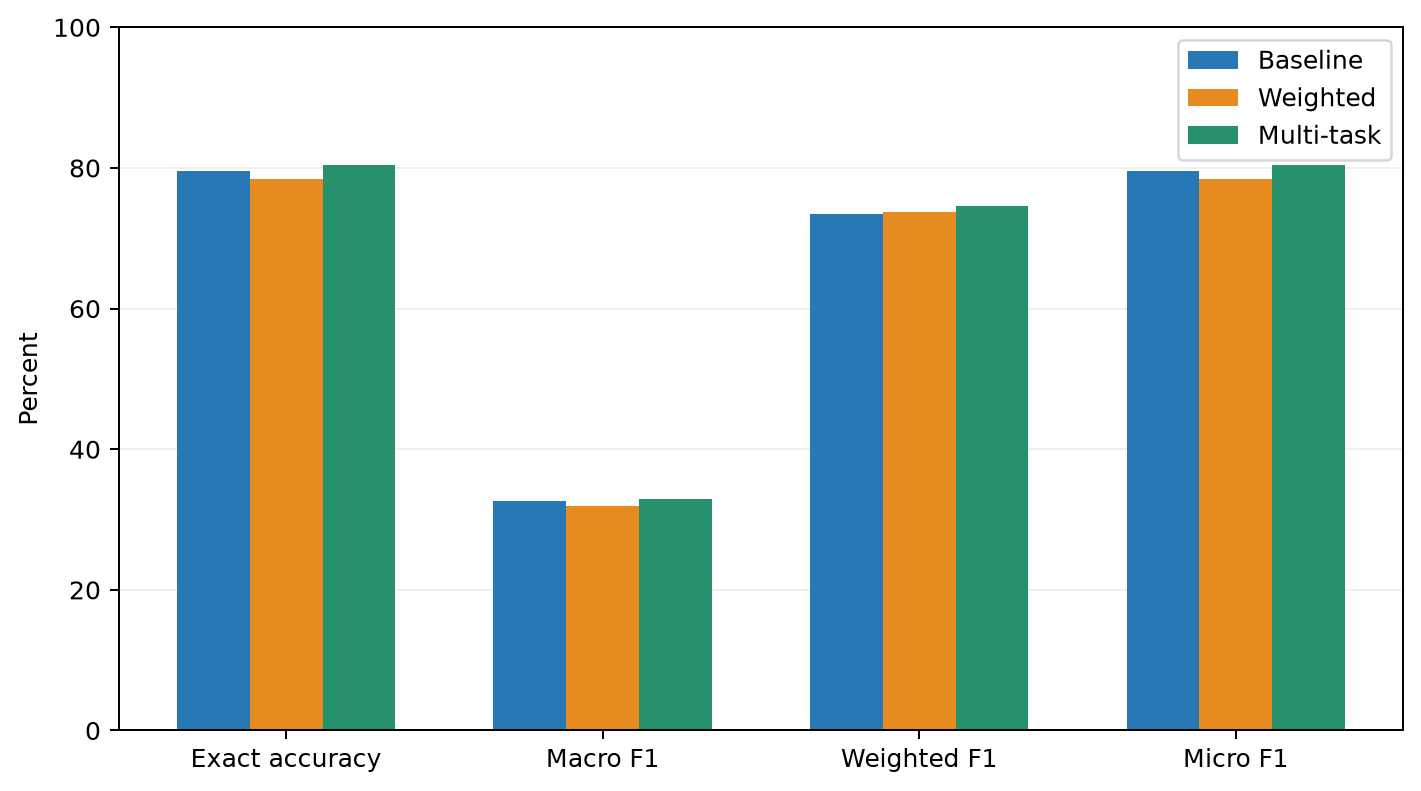

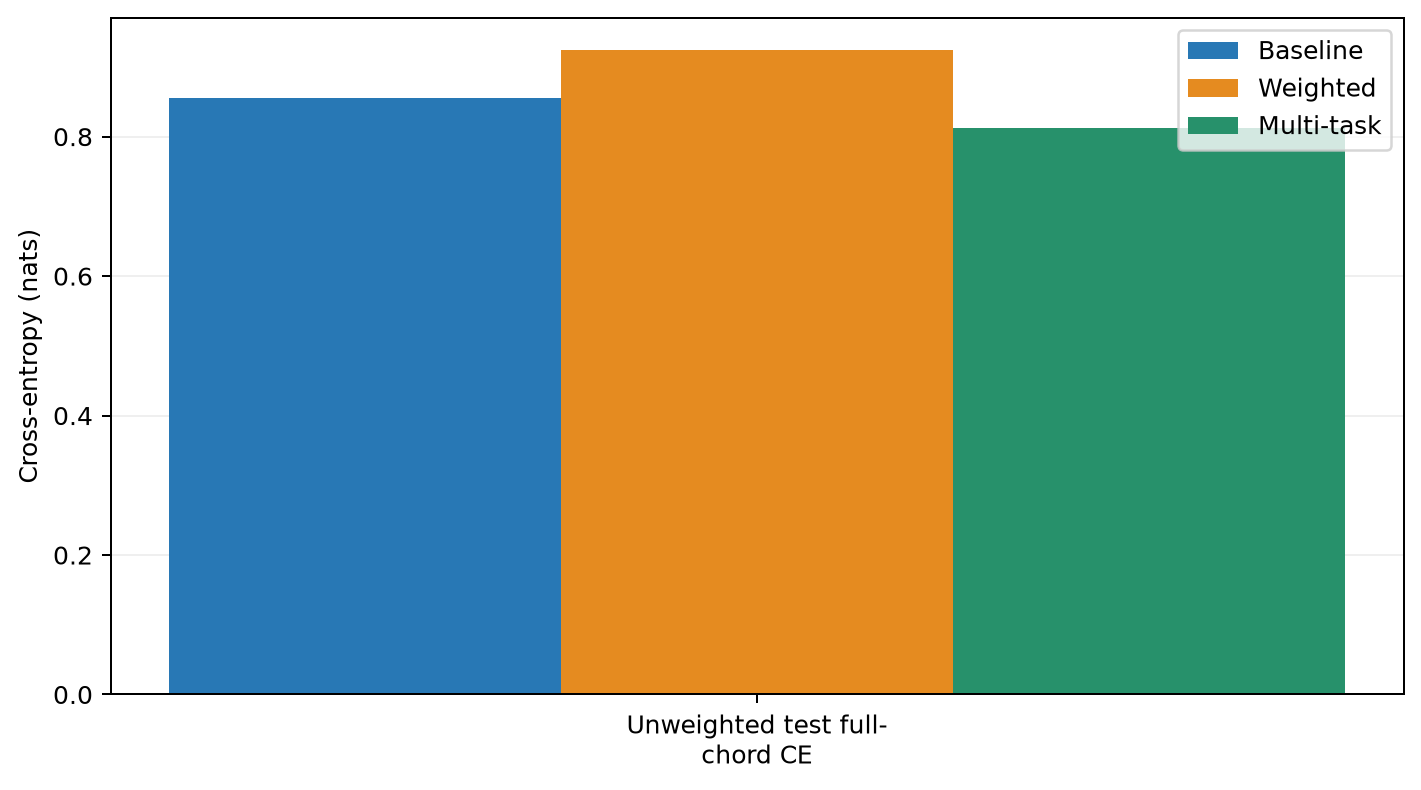

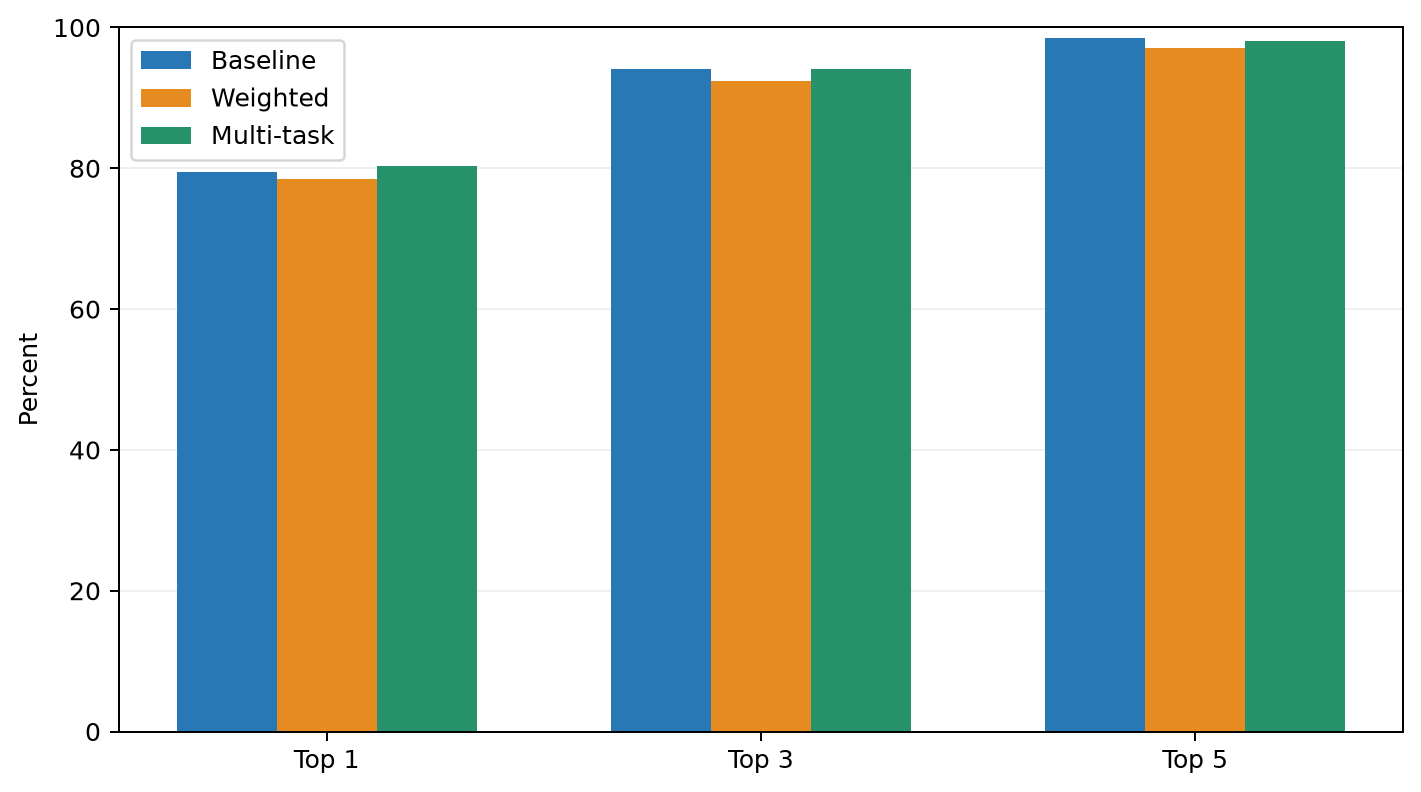

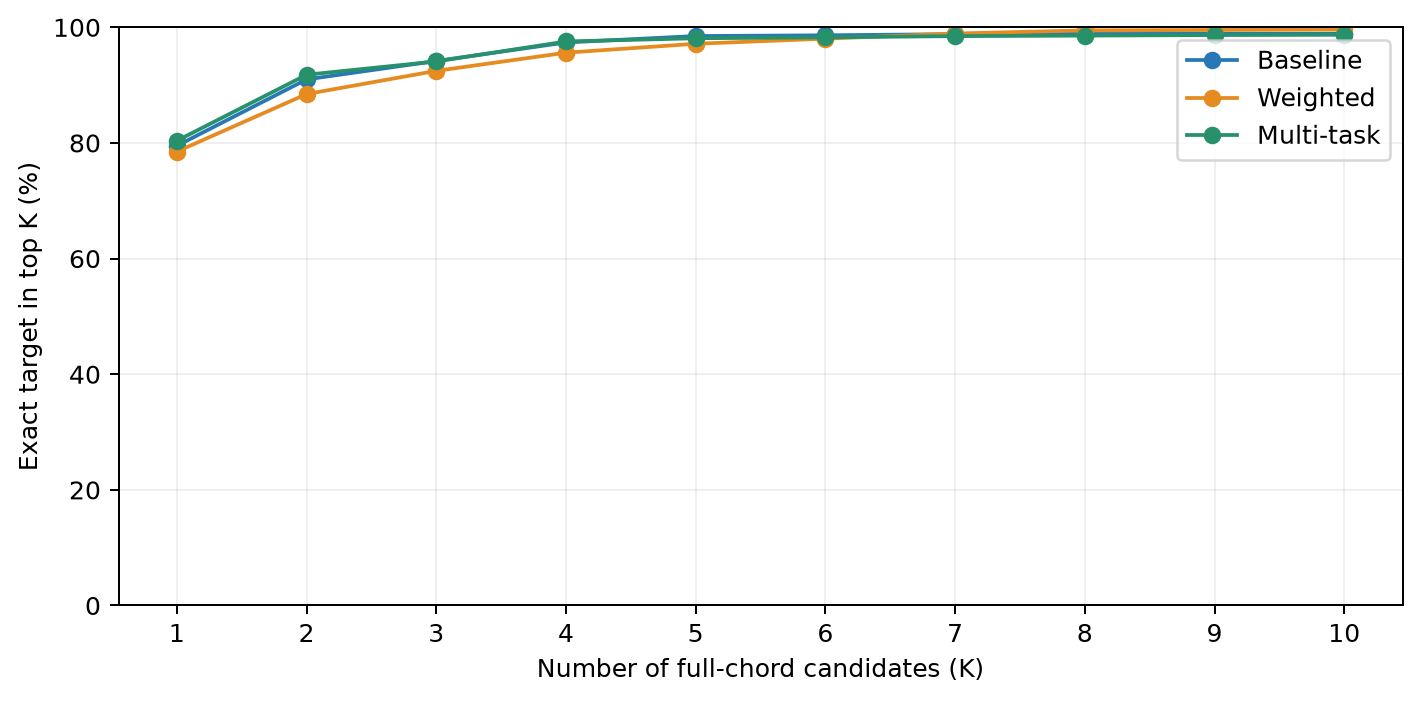

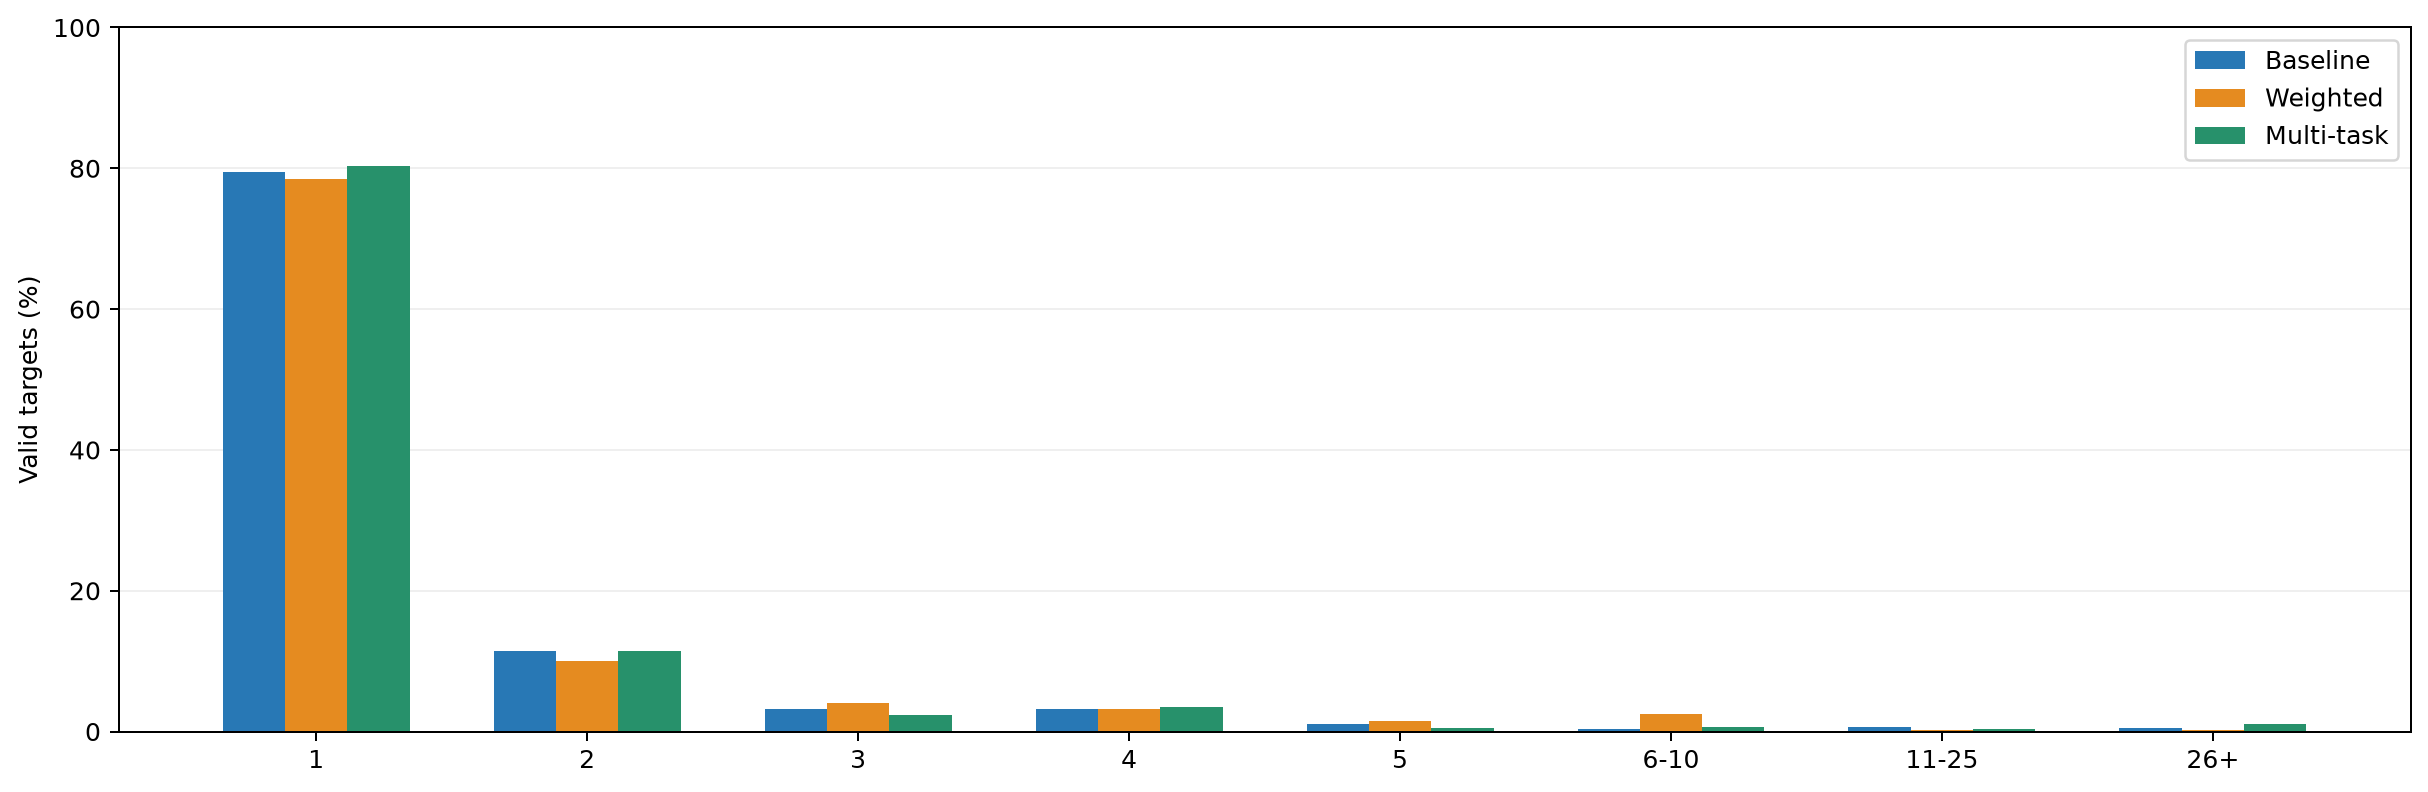

**Objective comparison:** Multi-task has the highest measured exact accuracy; Baseline has the highest exact top-3 retrieval. Candidate ranking and single-label accuracy serve different application goals. Macro F1 gives equal weight to supported complete classes and exposes weaknesses hidden by common classes.

In [12]:
figure_names=make_figures(study)
print('Saved',len(figure_names),'comparison figures plus the overview diagram.')
def show_figures(names):
    for name in names:display(Image(filename=str(study.figures/(name+'.png'))))
show_figures(['overall_classification','test_cross_entropy','top_k_accuracy','top_k_curves','reference_rank_distribution'])
best_acc=max(MODELS,key=lambda n:study.results[n]['metrics']['accuracy'])
best_top3=max(MODELS,key=lambda n:study.results[n]['metrics']['top3_accuracy'])
display(Markdown(f'**Objective comparison:** {DISPLAY[best_acc]} has the highest measured exact accuracy; {DISPLAY[best_top3]} has the highest exact top-3 retrieval. Candidate ranking and single-label accuracy serve different application goals. Macro F1 gives equal weight to supported complete classes and exposes weaknesses hidden by common classes.'))

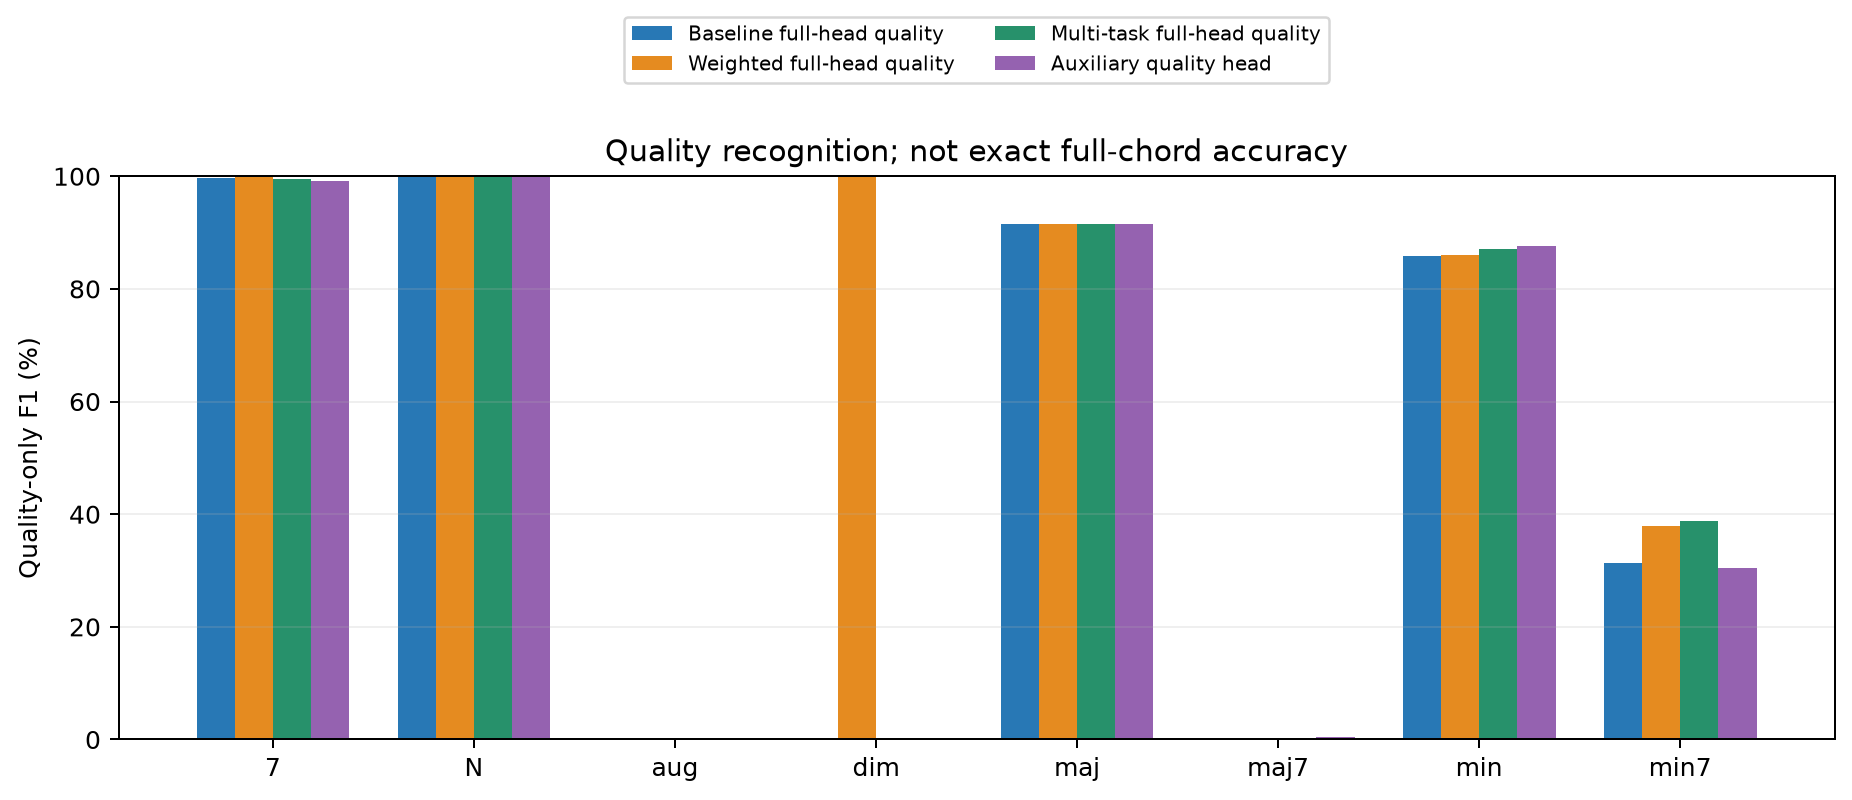

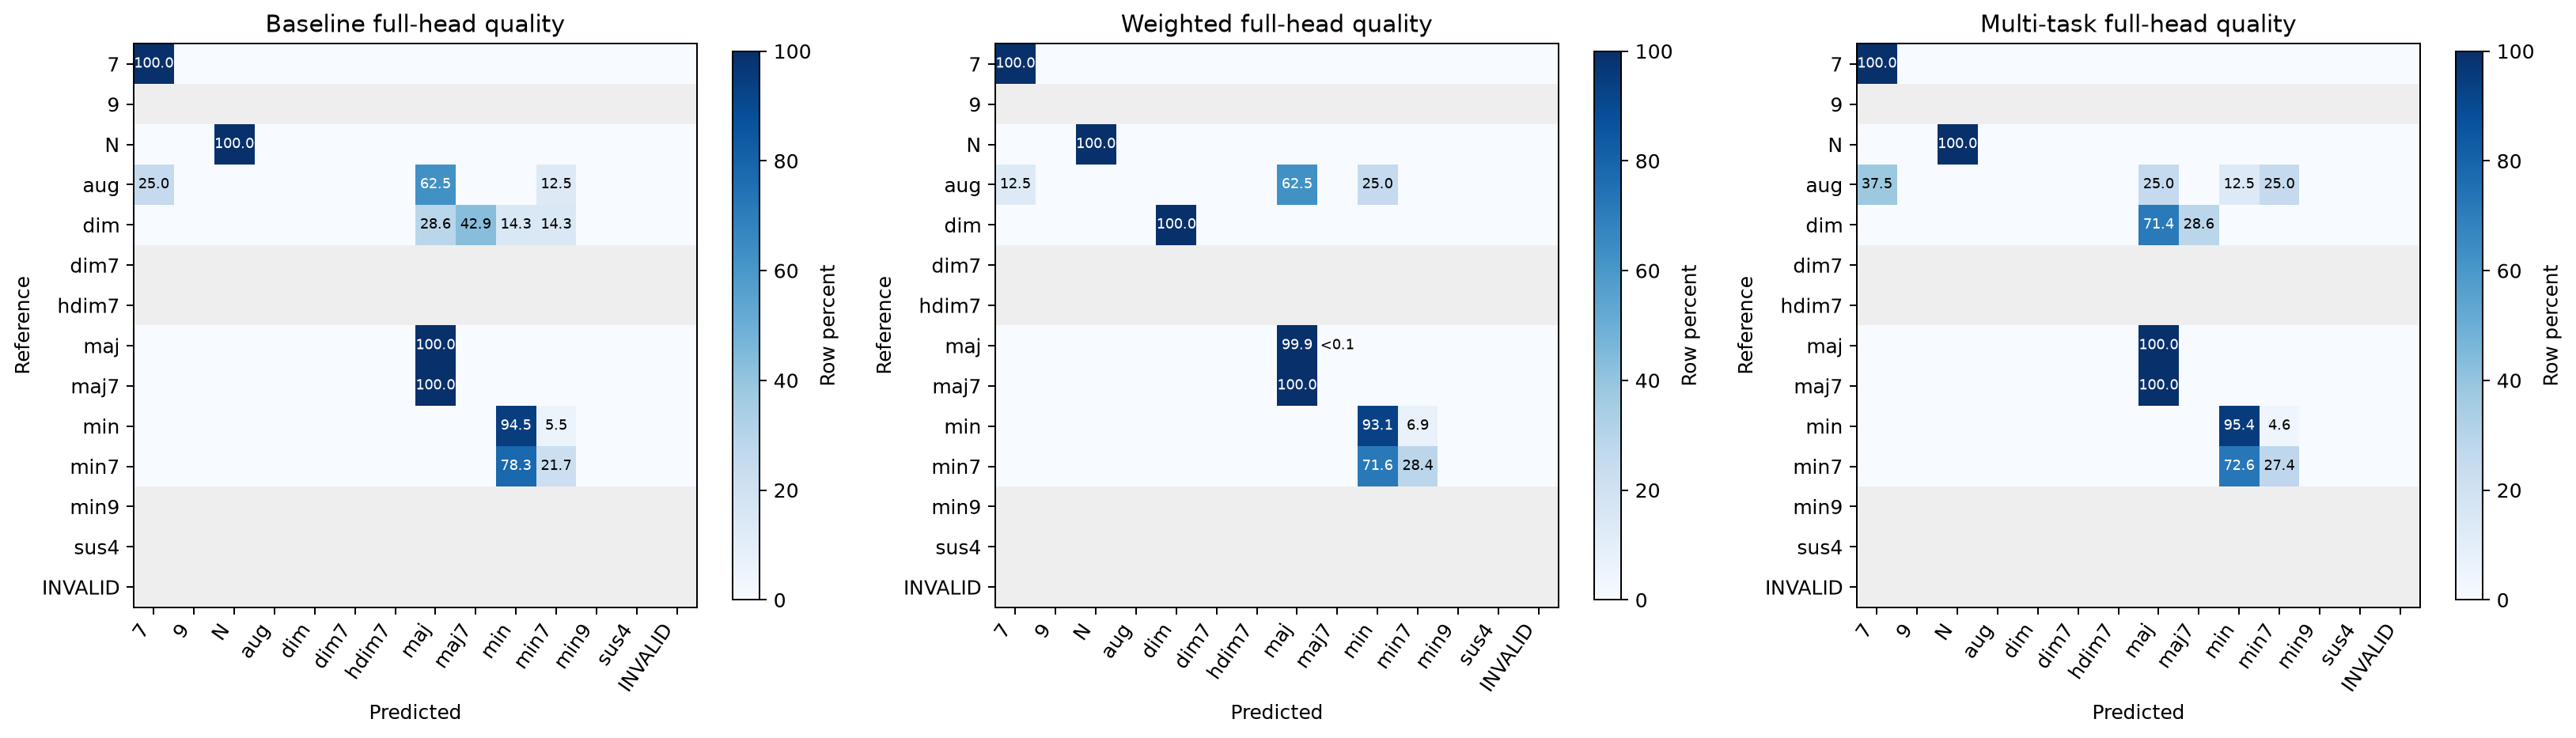

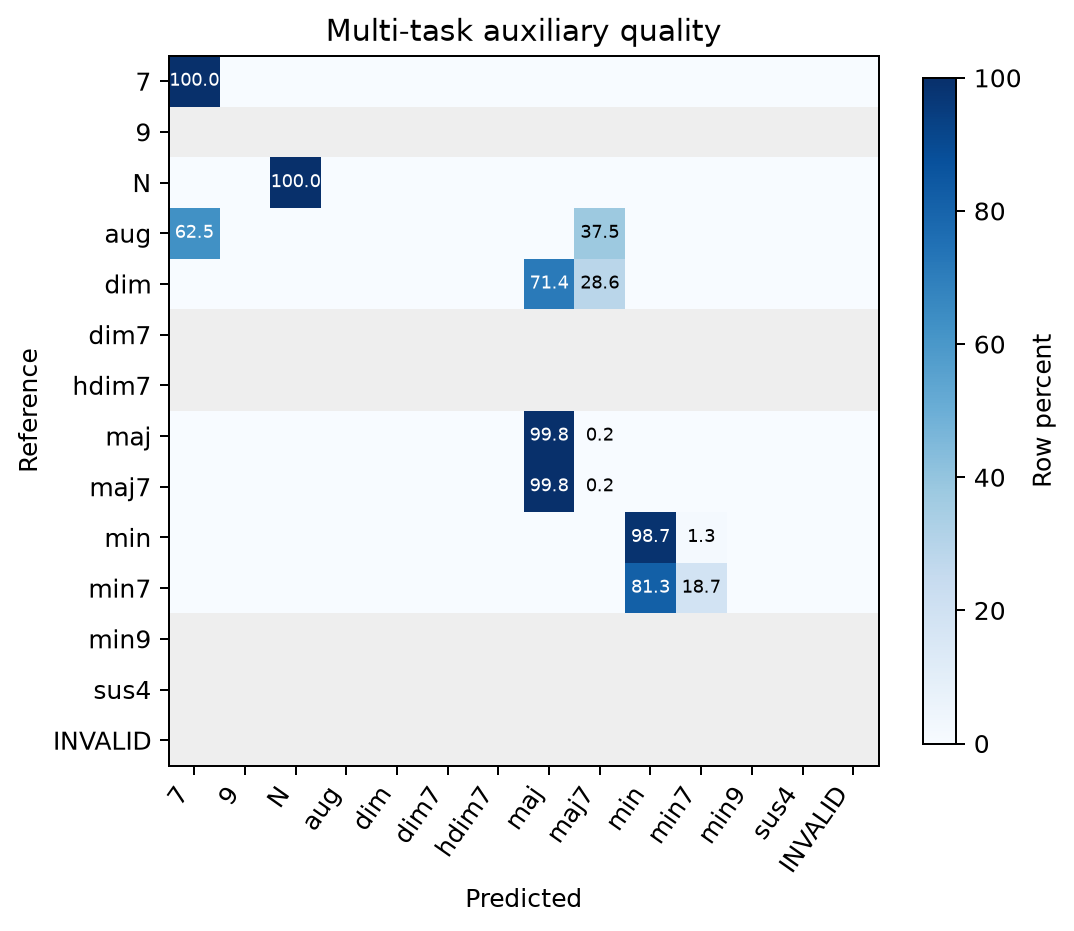

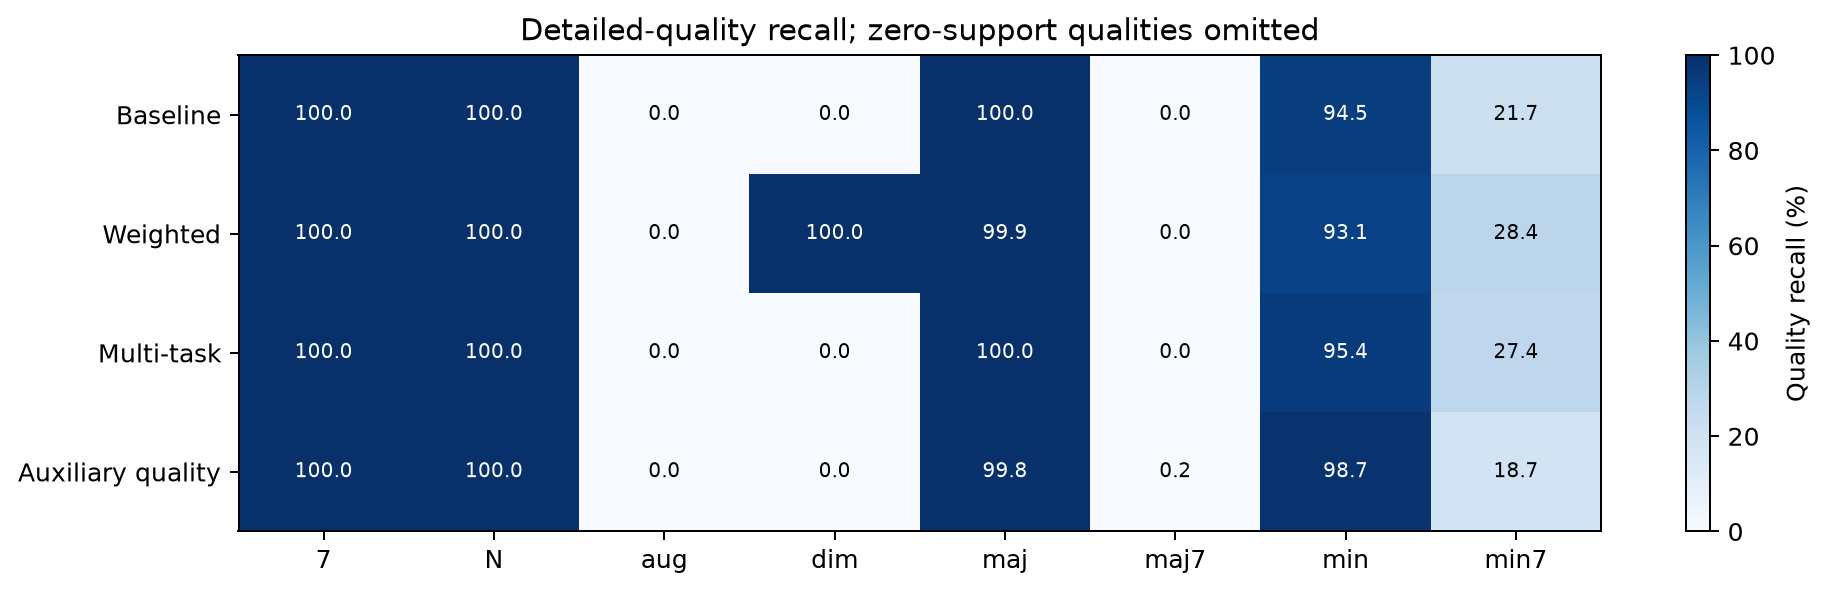

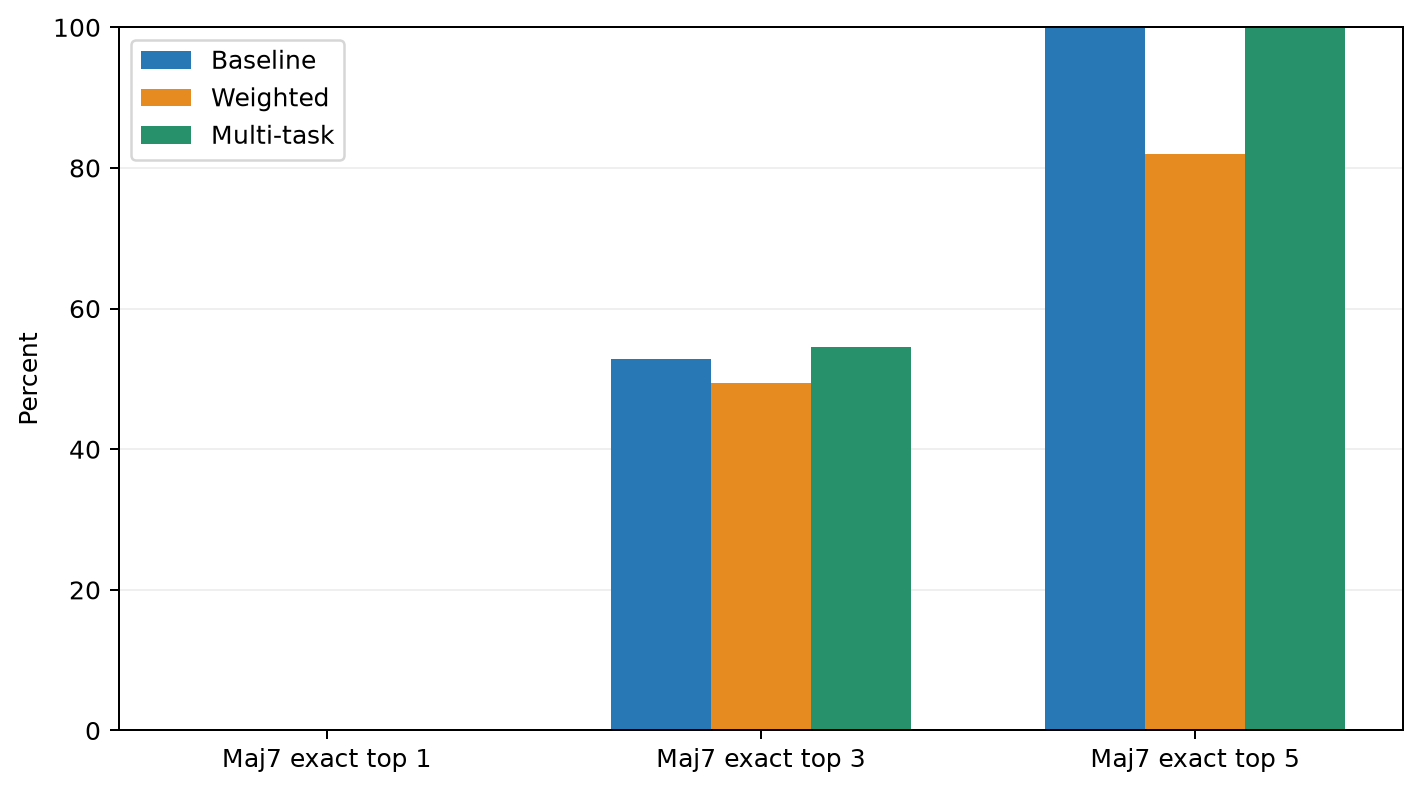

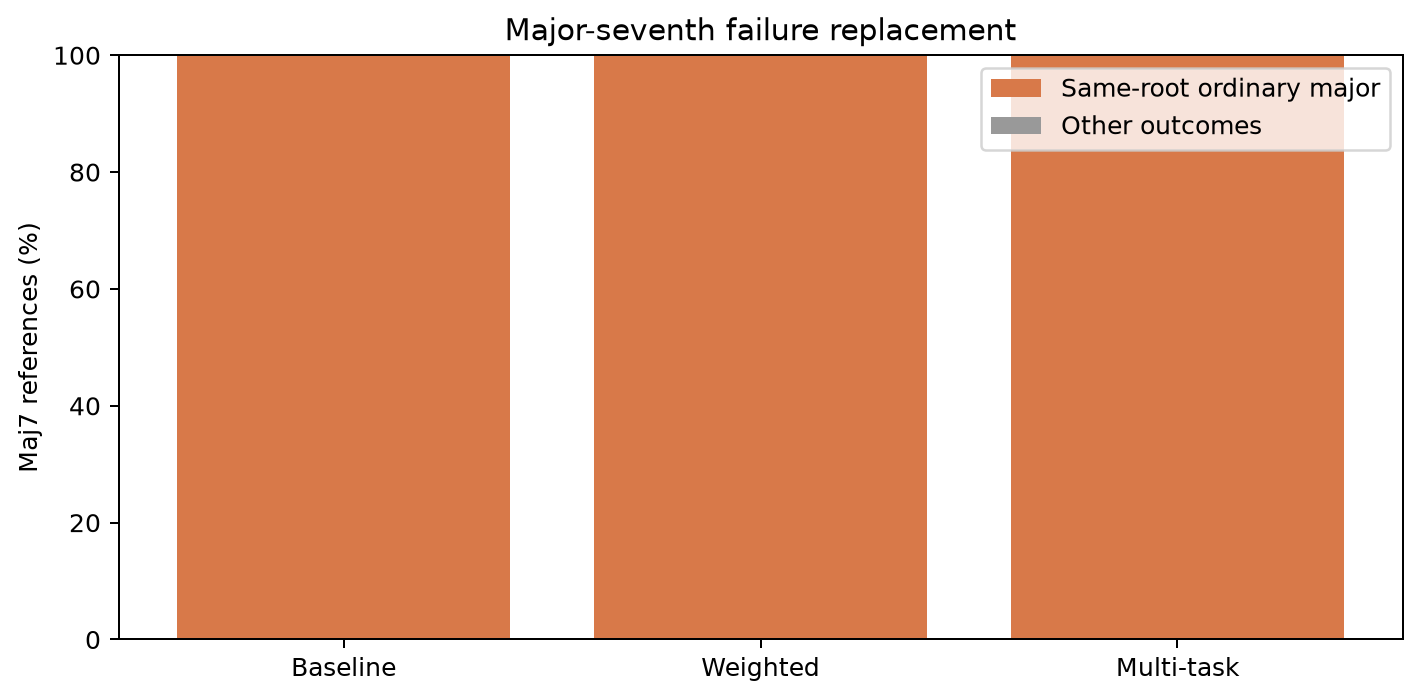

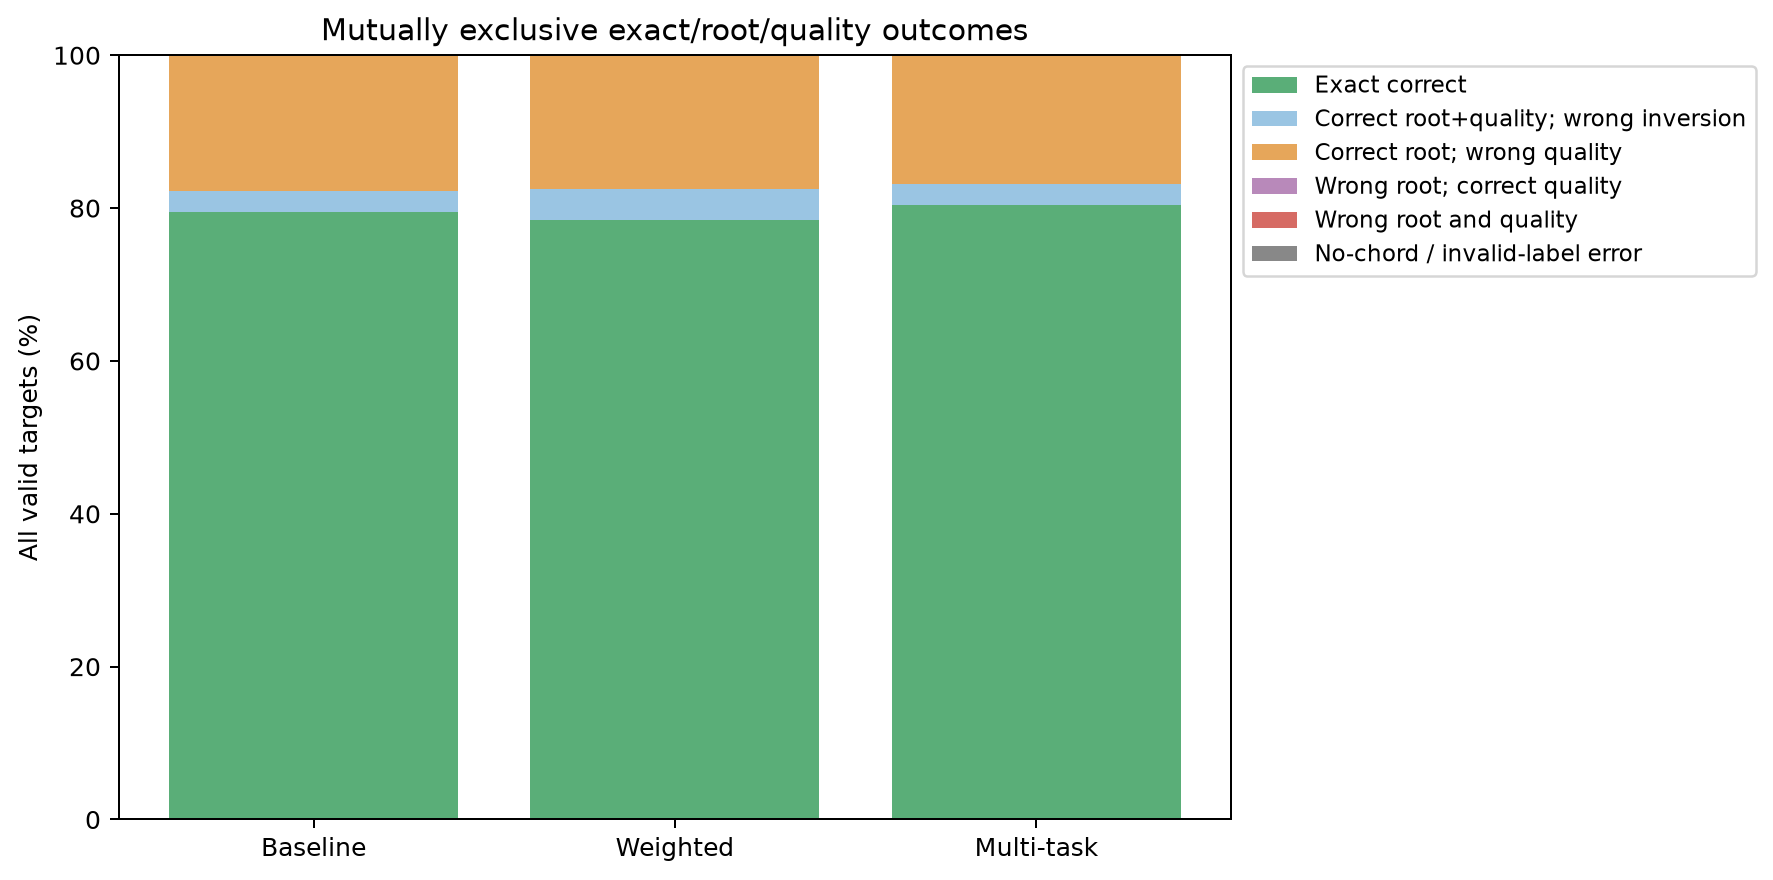

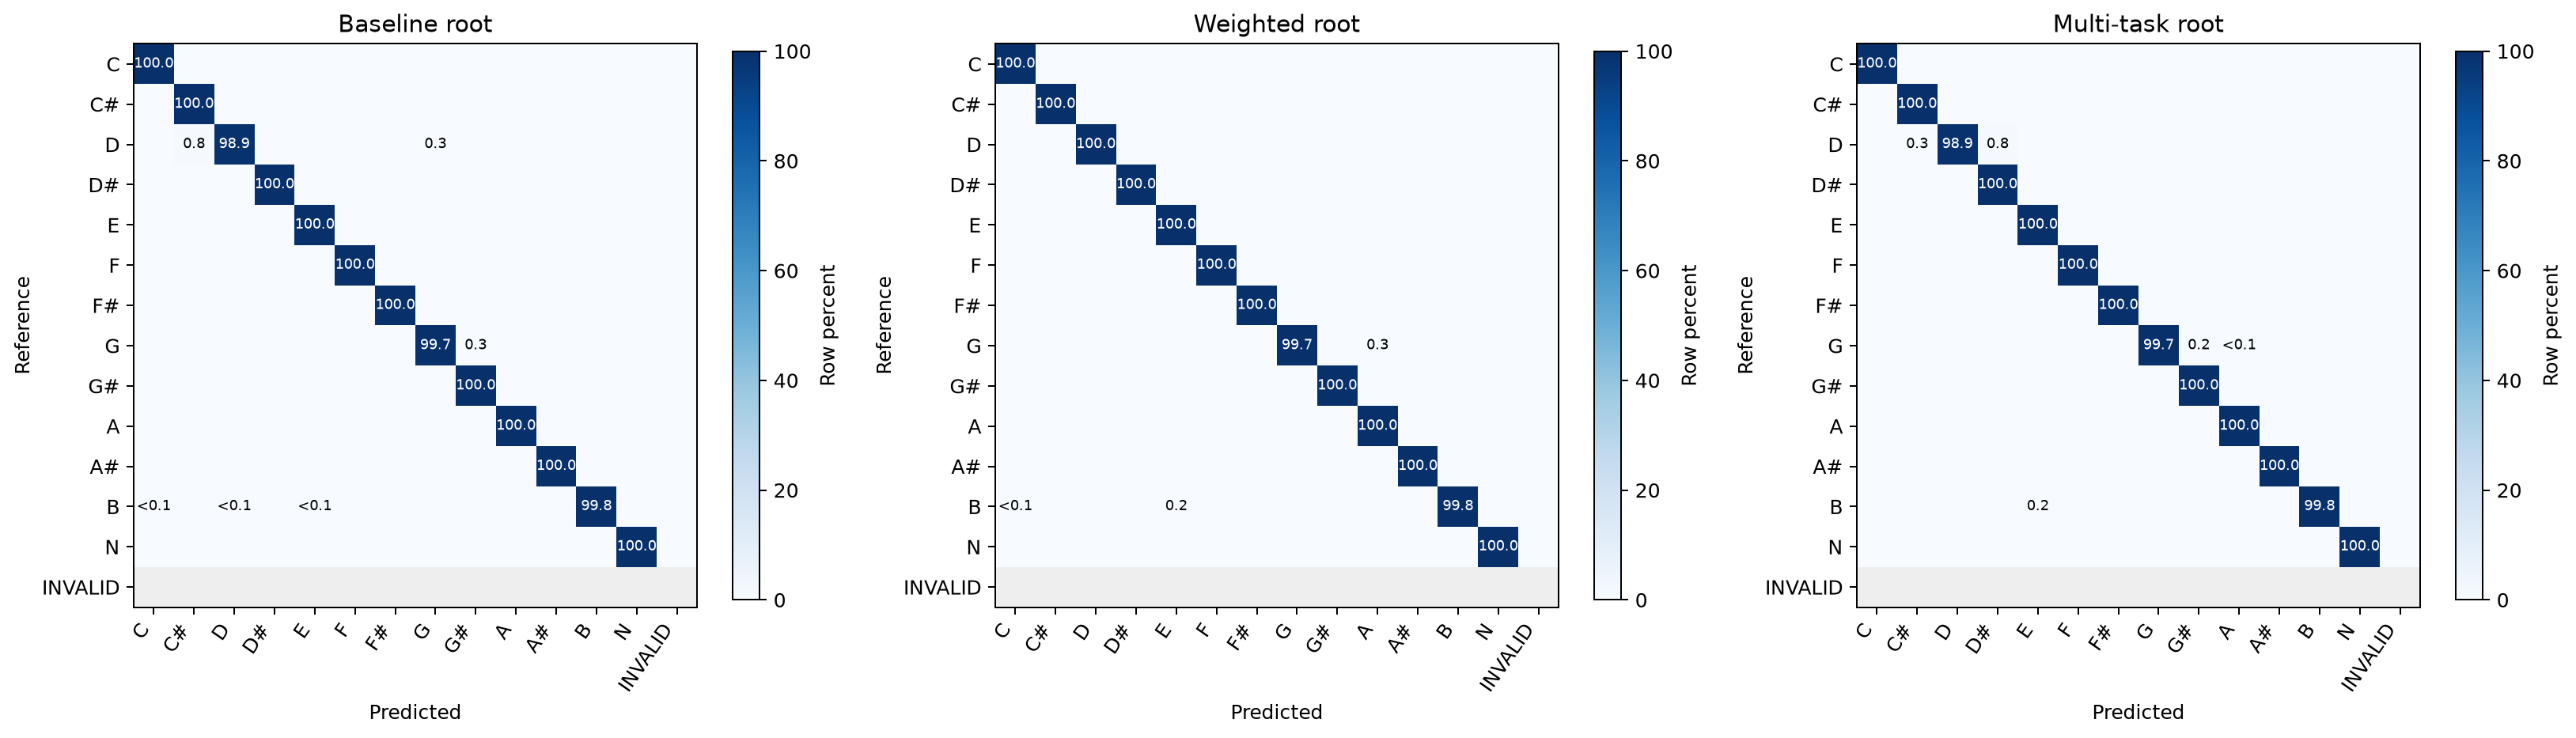

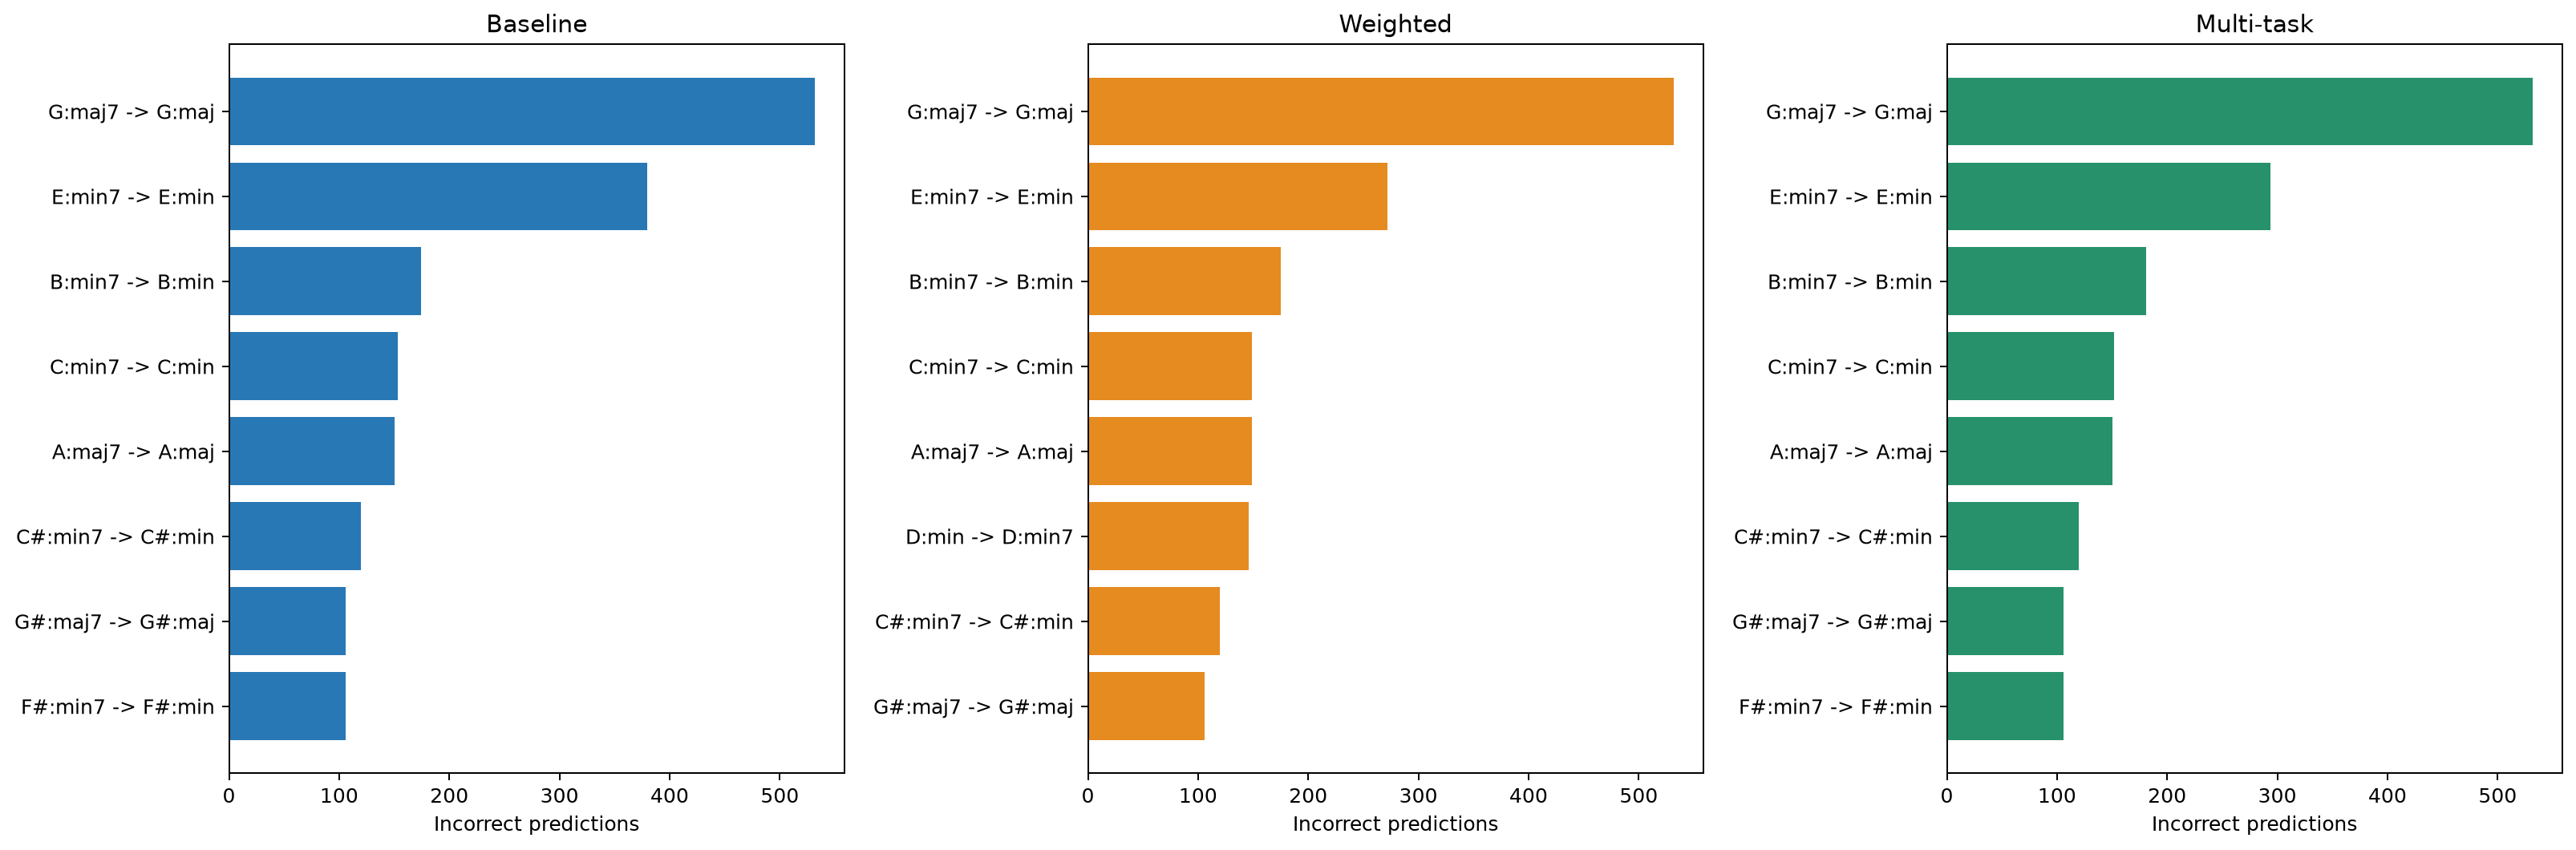

**Quality/errors:** inspect support before interpreting rare-quality results. Full-head-implied quality and auxiliary quality are separate. Maj7 ranking improvements without top-1 successes do not solve exact major-seventh refinement. Error slices partition all targets; maj7/rare subsets are not added again.

In [13]:
show_figures(['per_quality_f1','quality_confusions','auxiliary_quality_confusion','quality_recall_heatmap','maj7_candidate_accuracy','maj7_failure_replacements','error_category_stack','root_confusions','most_confused_chord_pairs'])
display(Markdown('**Quality/errors:** inspect support before interpreting rare-quality results. Full-head-implied quality and auxiliary quality are separate. Maj7 ranking improvements without top-1 successes do not solve exact major-seventh refinement. Error slices partition all targets; maj7/rare subsets are not added again.'))

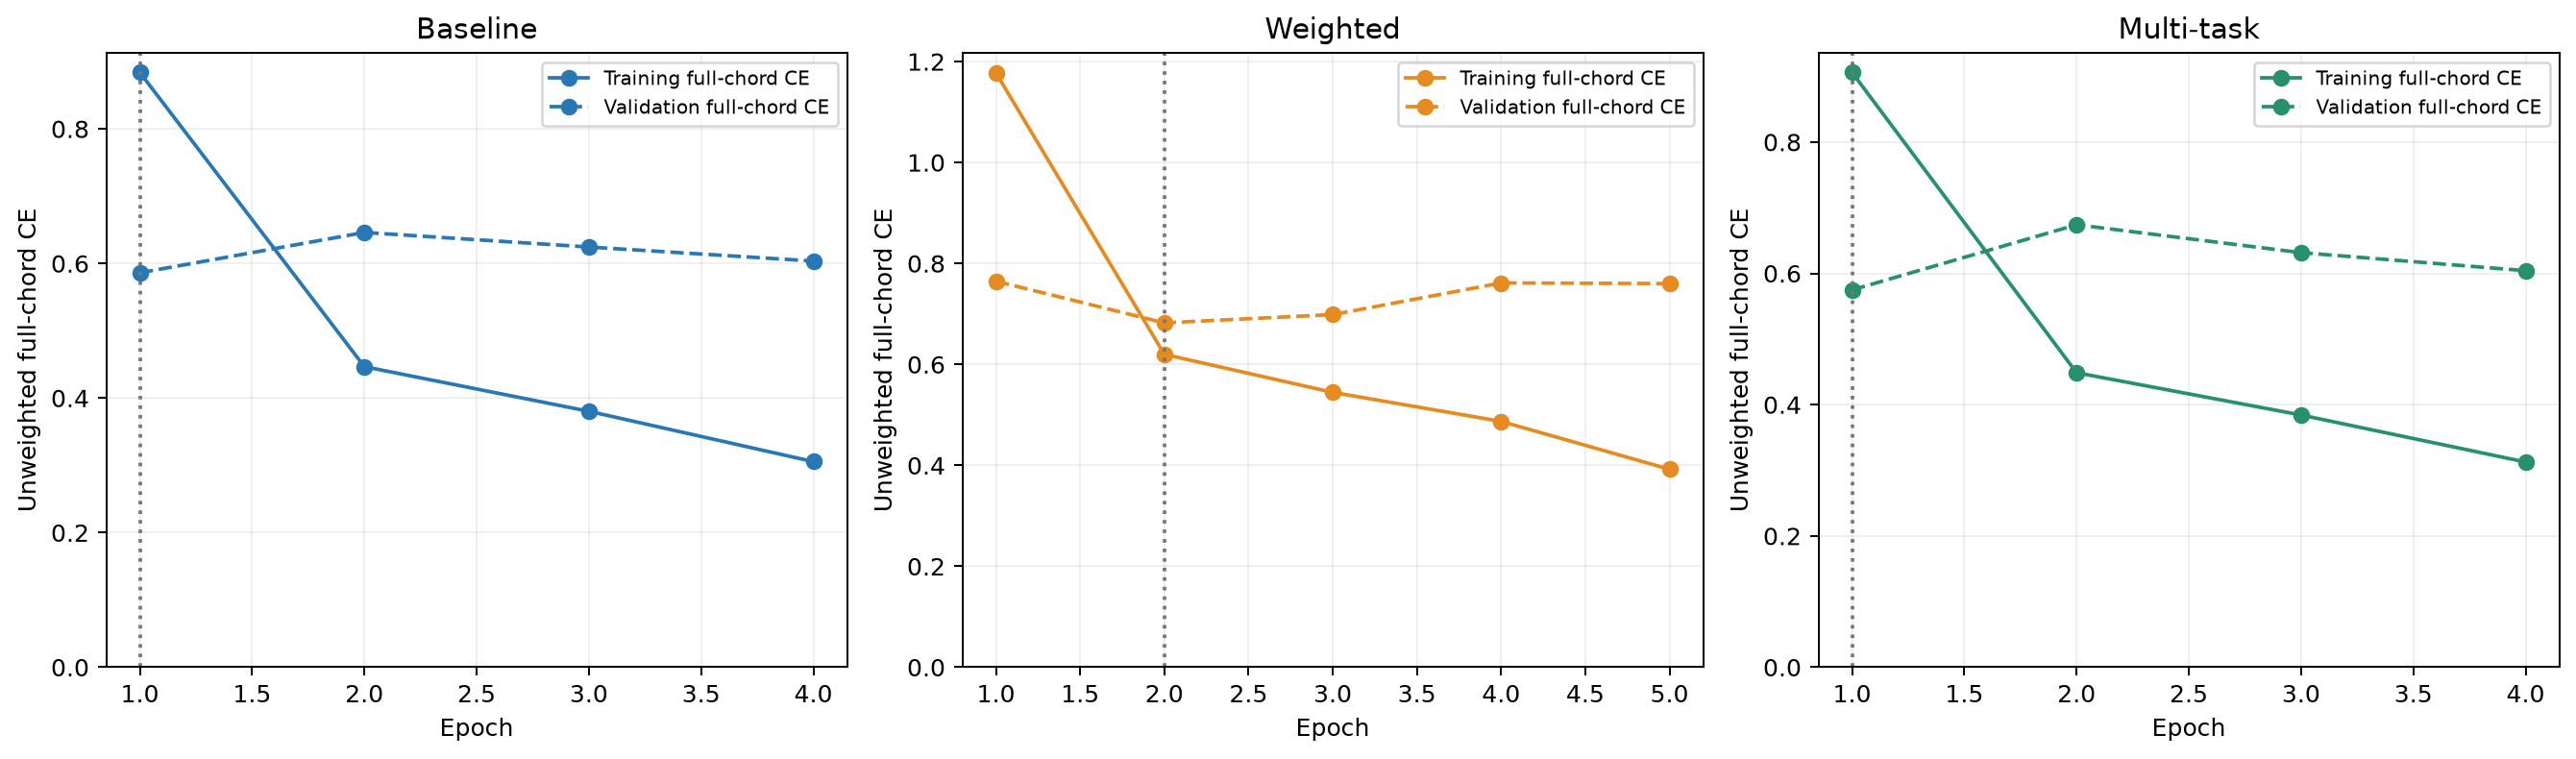

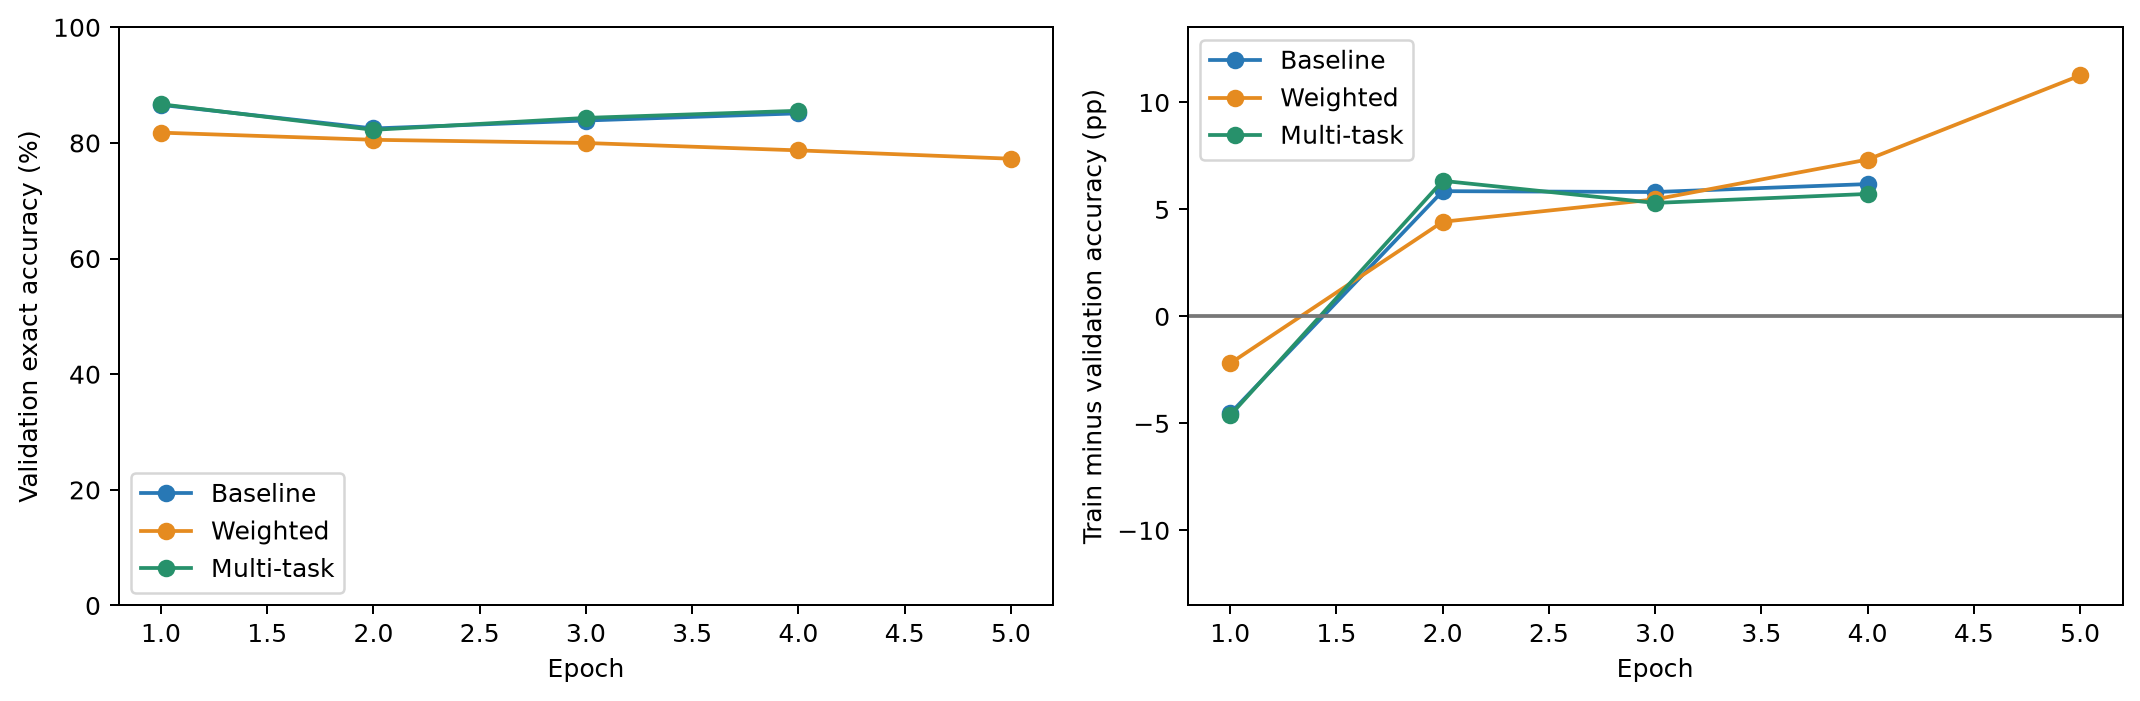

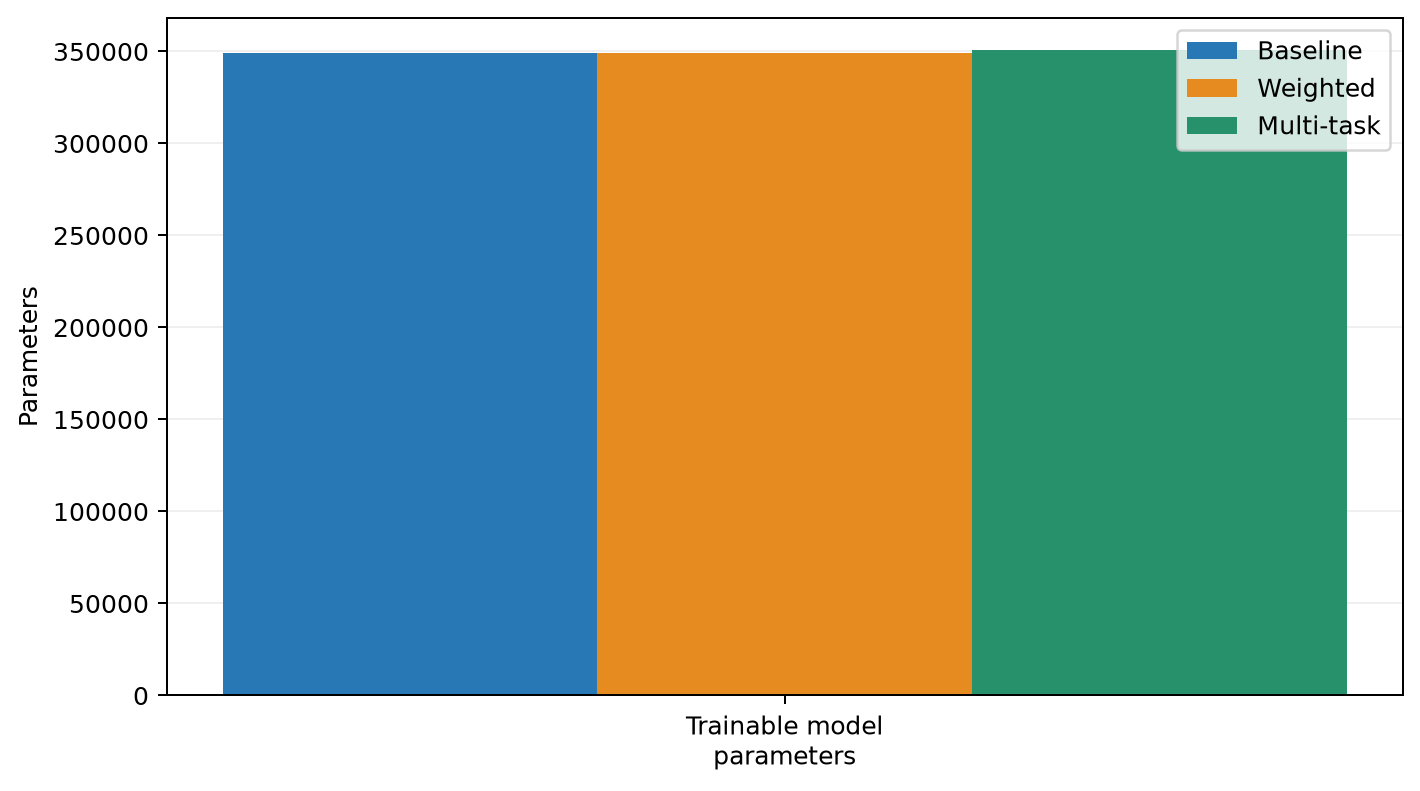

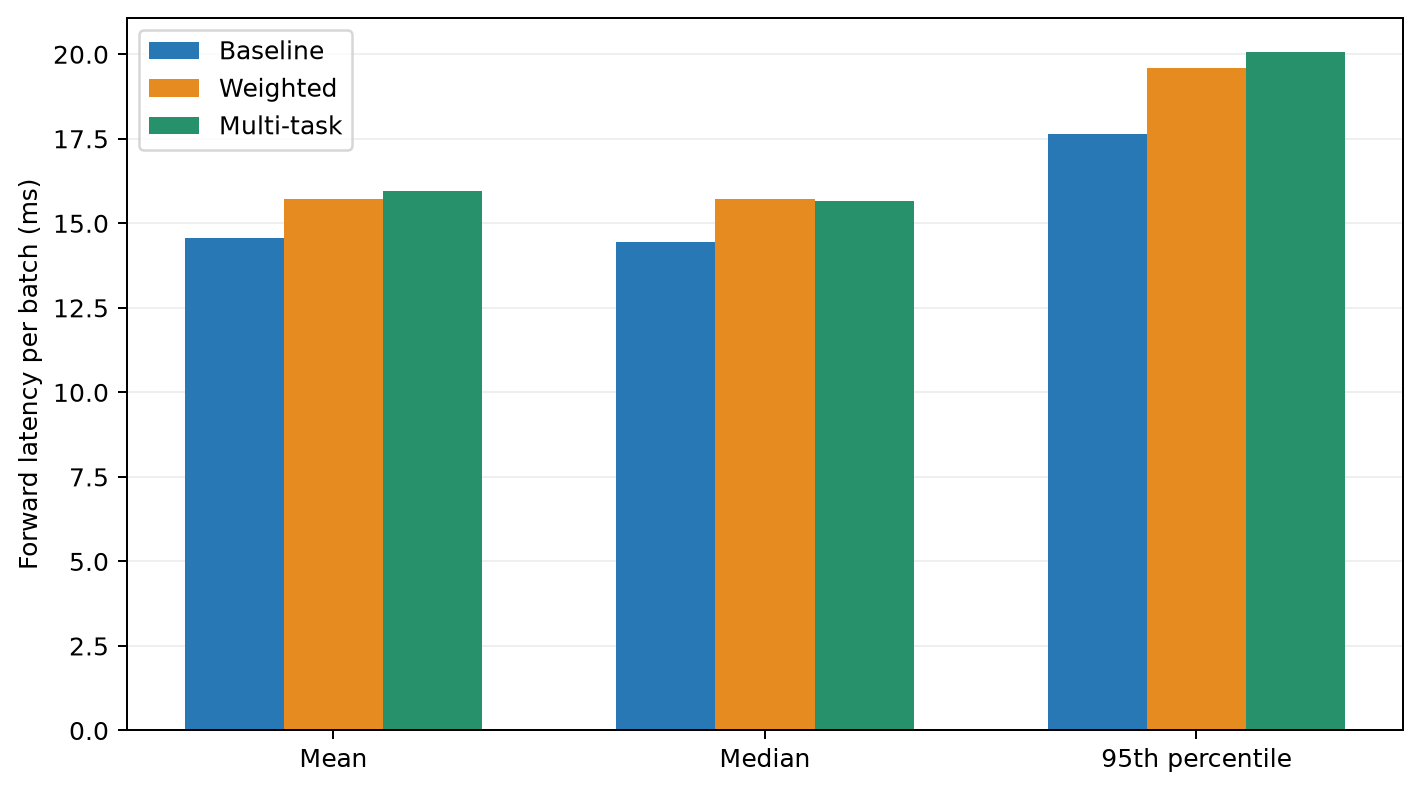

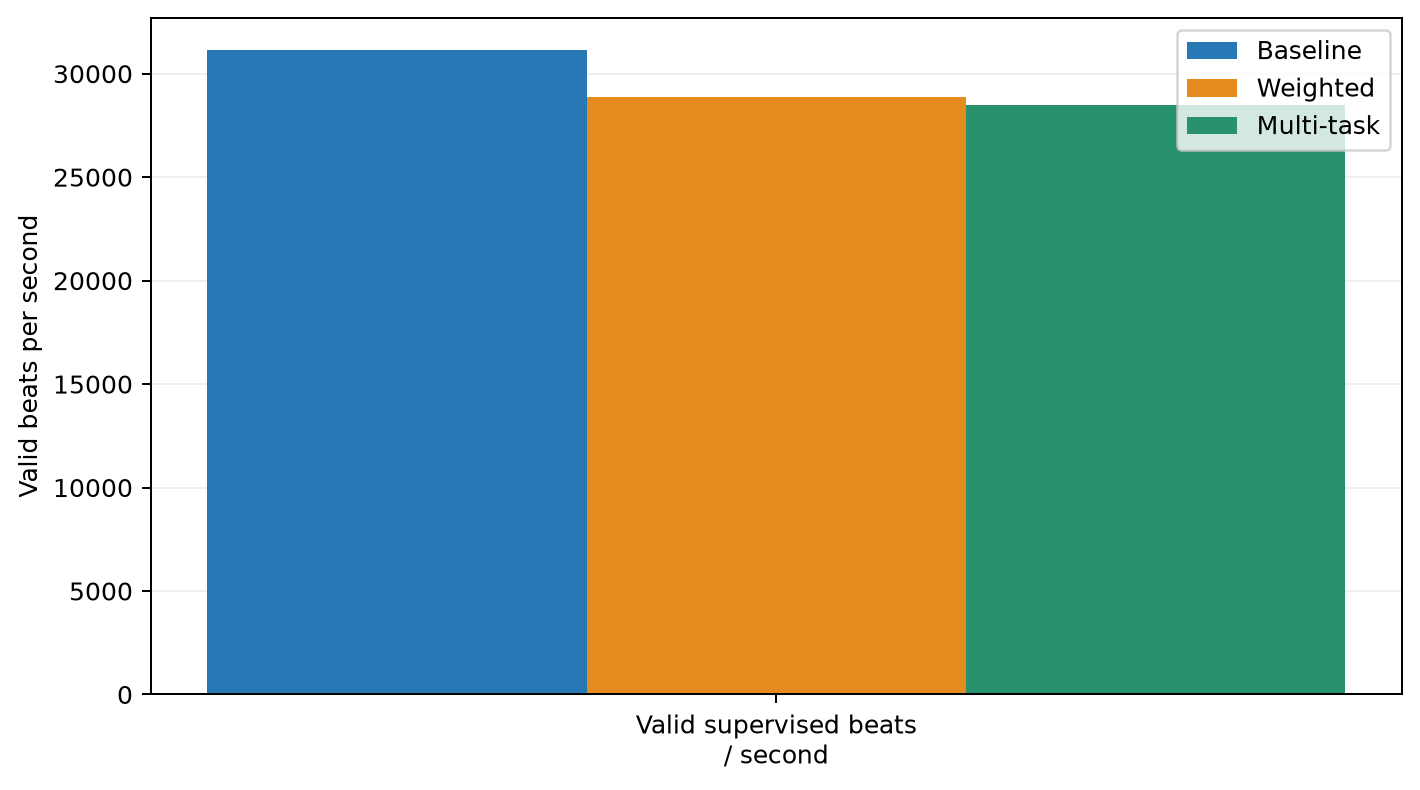

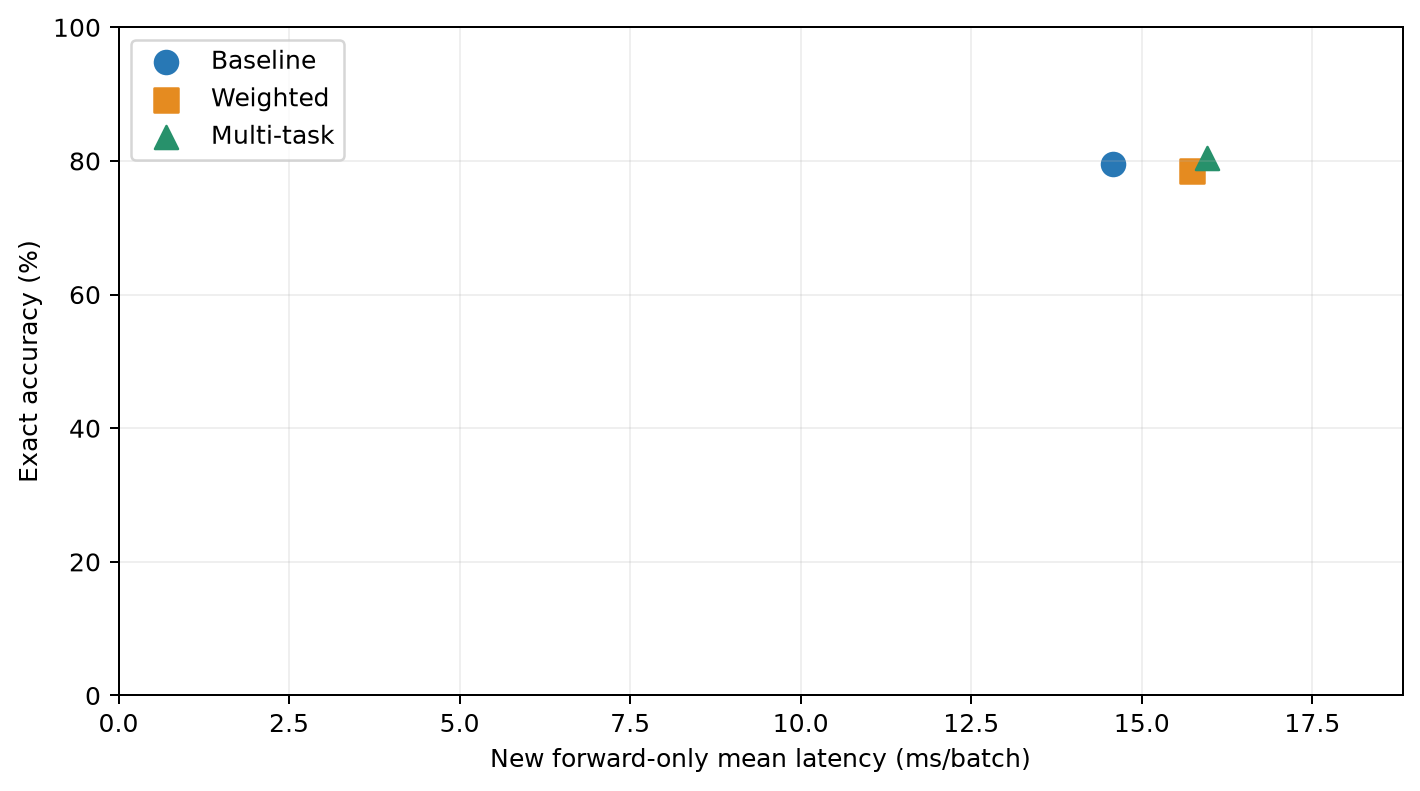

**Training/efficiency:** selected epochs follow unweighted validation CE, not test accuracy. Training objectives differ, so only full-chord CE is compared directly. CPU benchmark noise can change latency ordering, particularly for the architecturally identical baseline and weighted models. Process memory is not tensor-only activation memory.

In [14]:
show_figures(['comparable_training_loss','validation_accuracy_and_gap','parameter_counts','inference_latency','inference_throughput','accuracy_latency_tradeoff'])
display(Markdown('**Training/efficiency:** selected epochs follow unweighted validation CE, not test accuracy. Training objectives differ, so only full-chord CE is compared directly. CPU benchmark noise can change latency ordering, particularly for the architecturally identical baseline and weighted models. Process memory is not tensor-only activation memory.'))

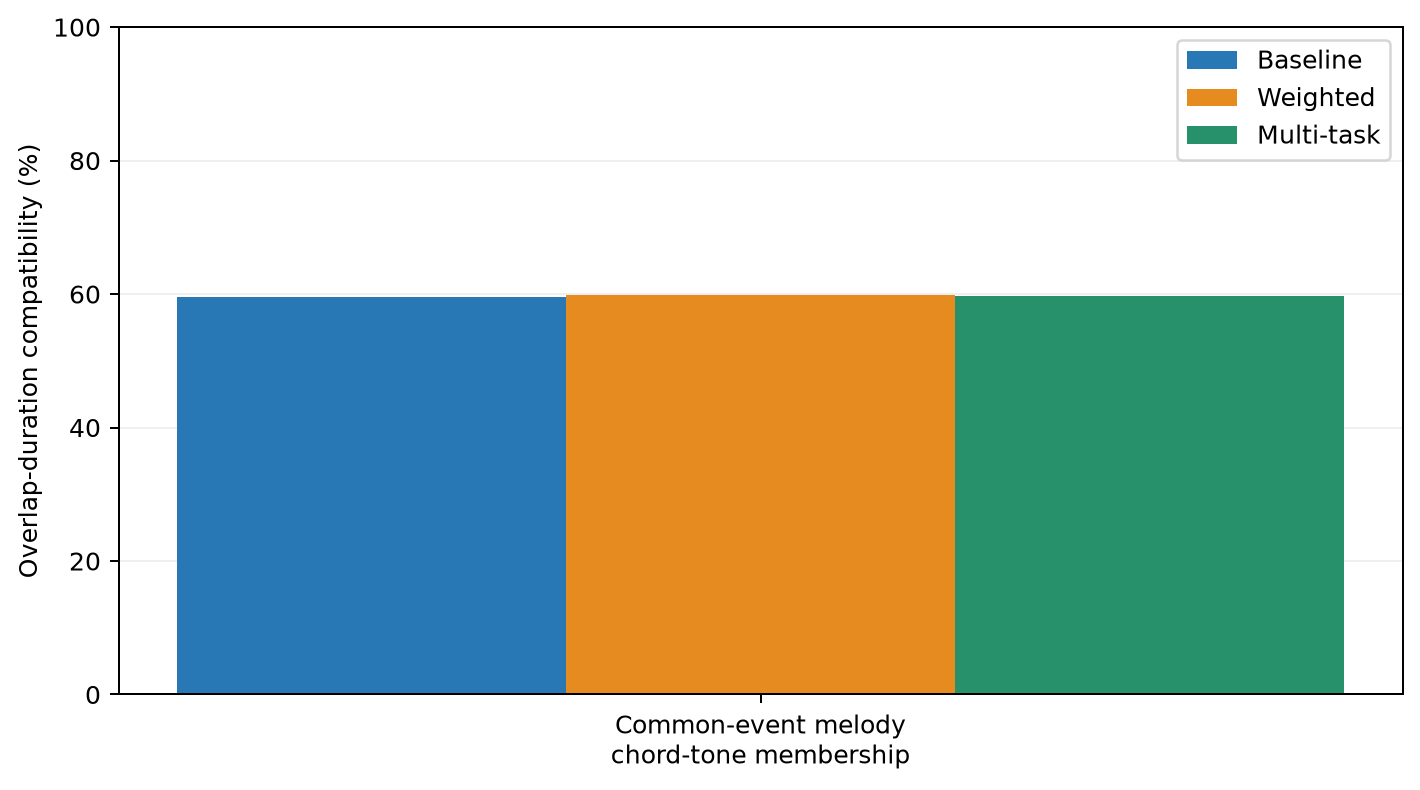

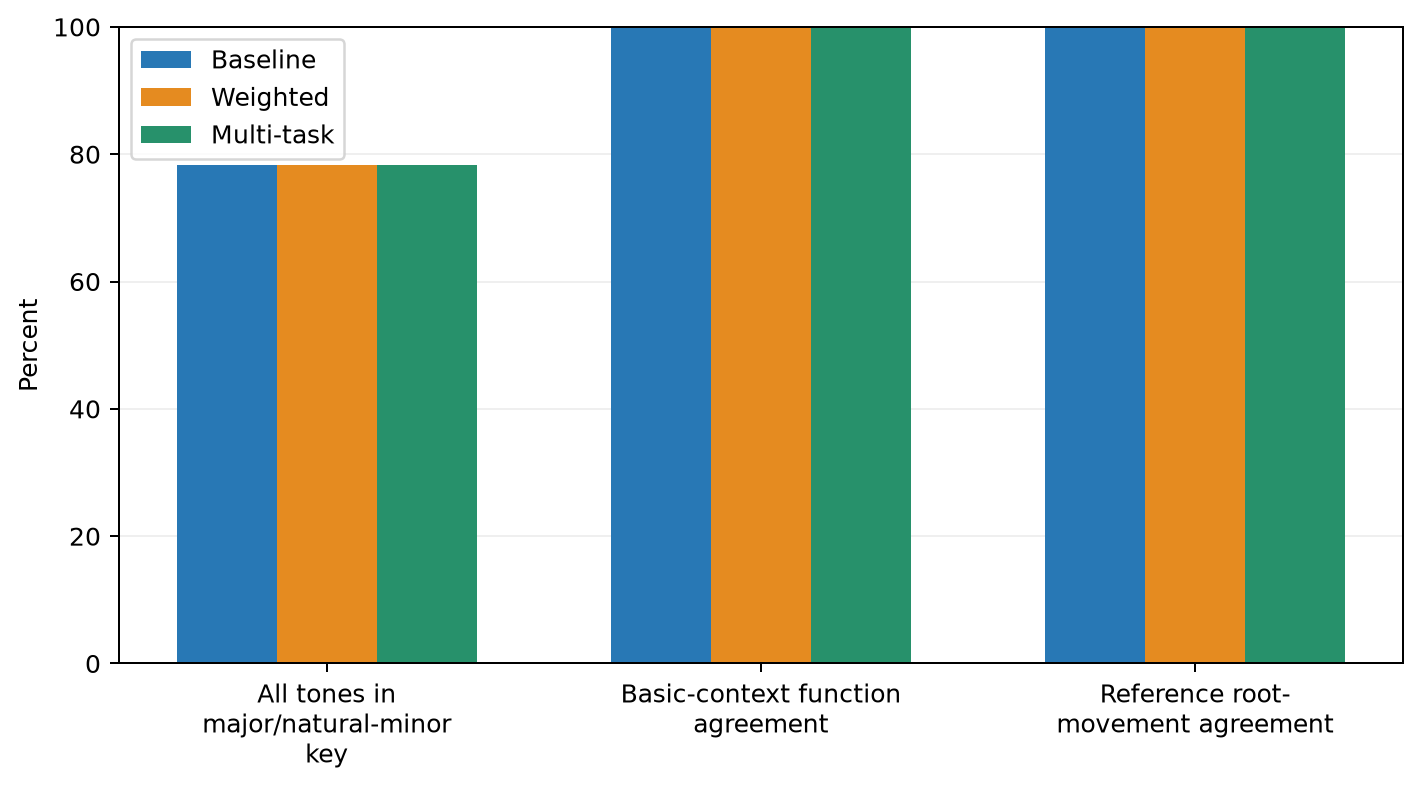

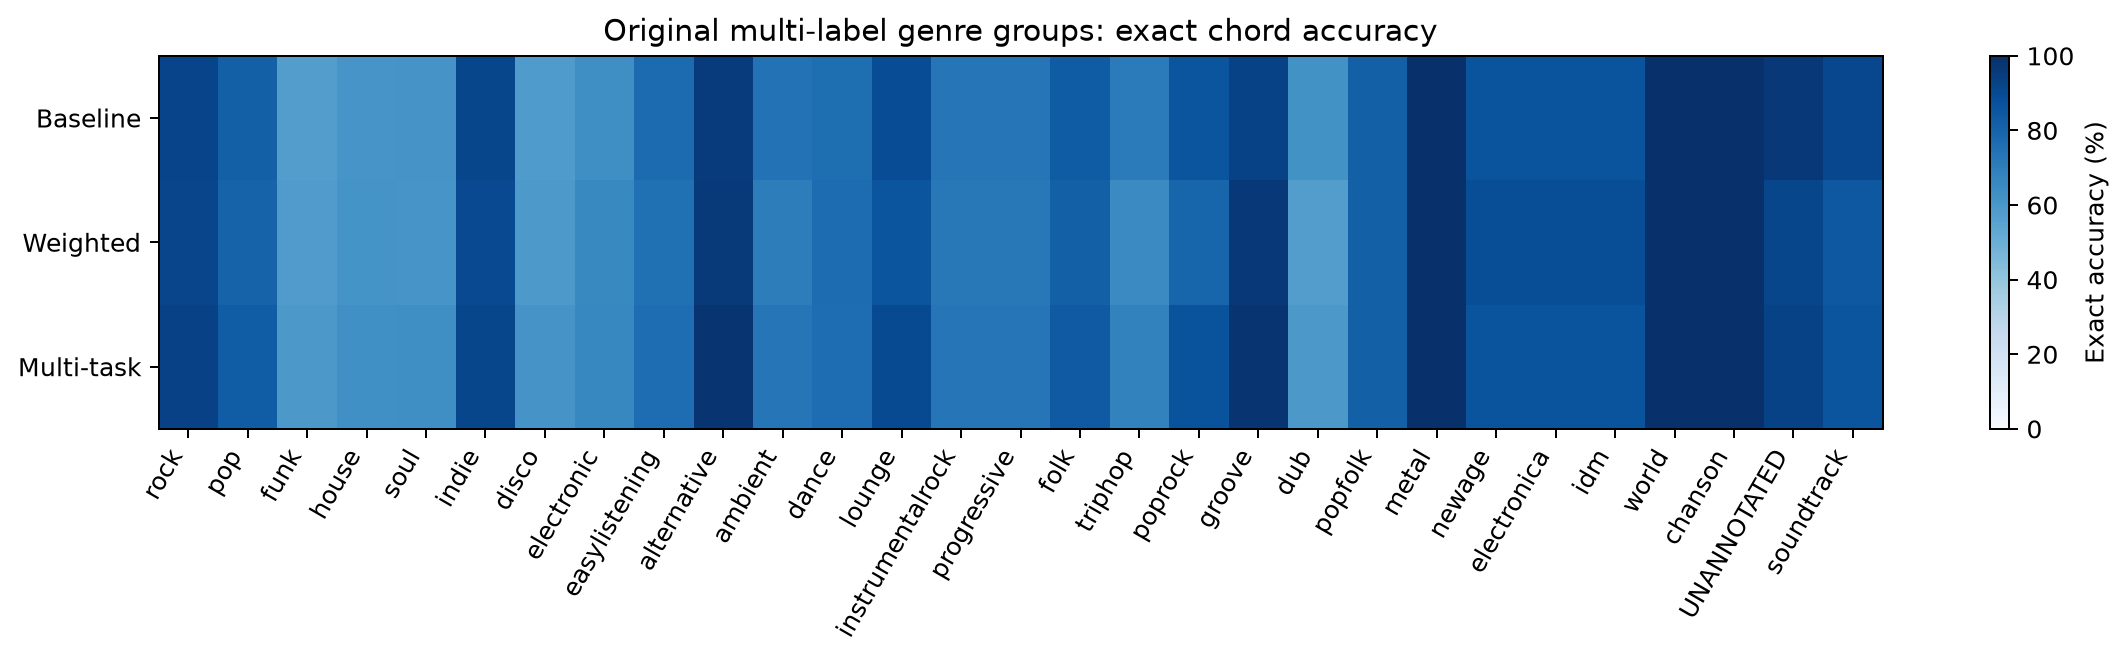

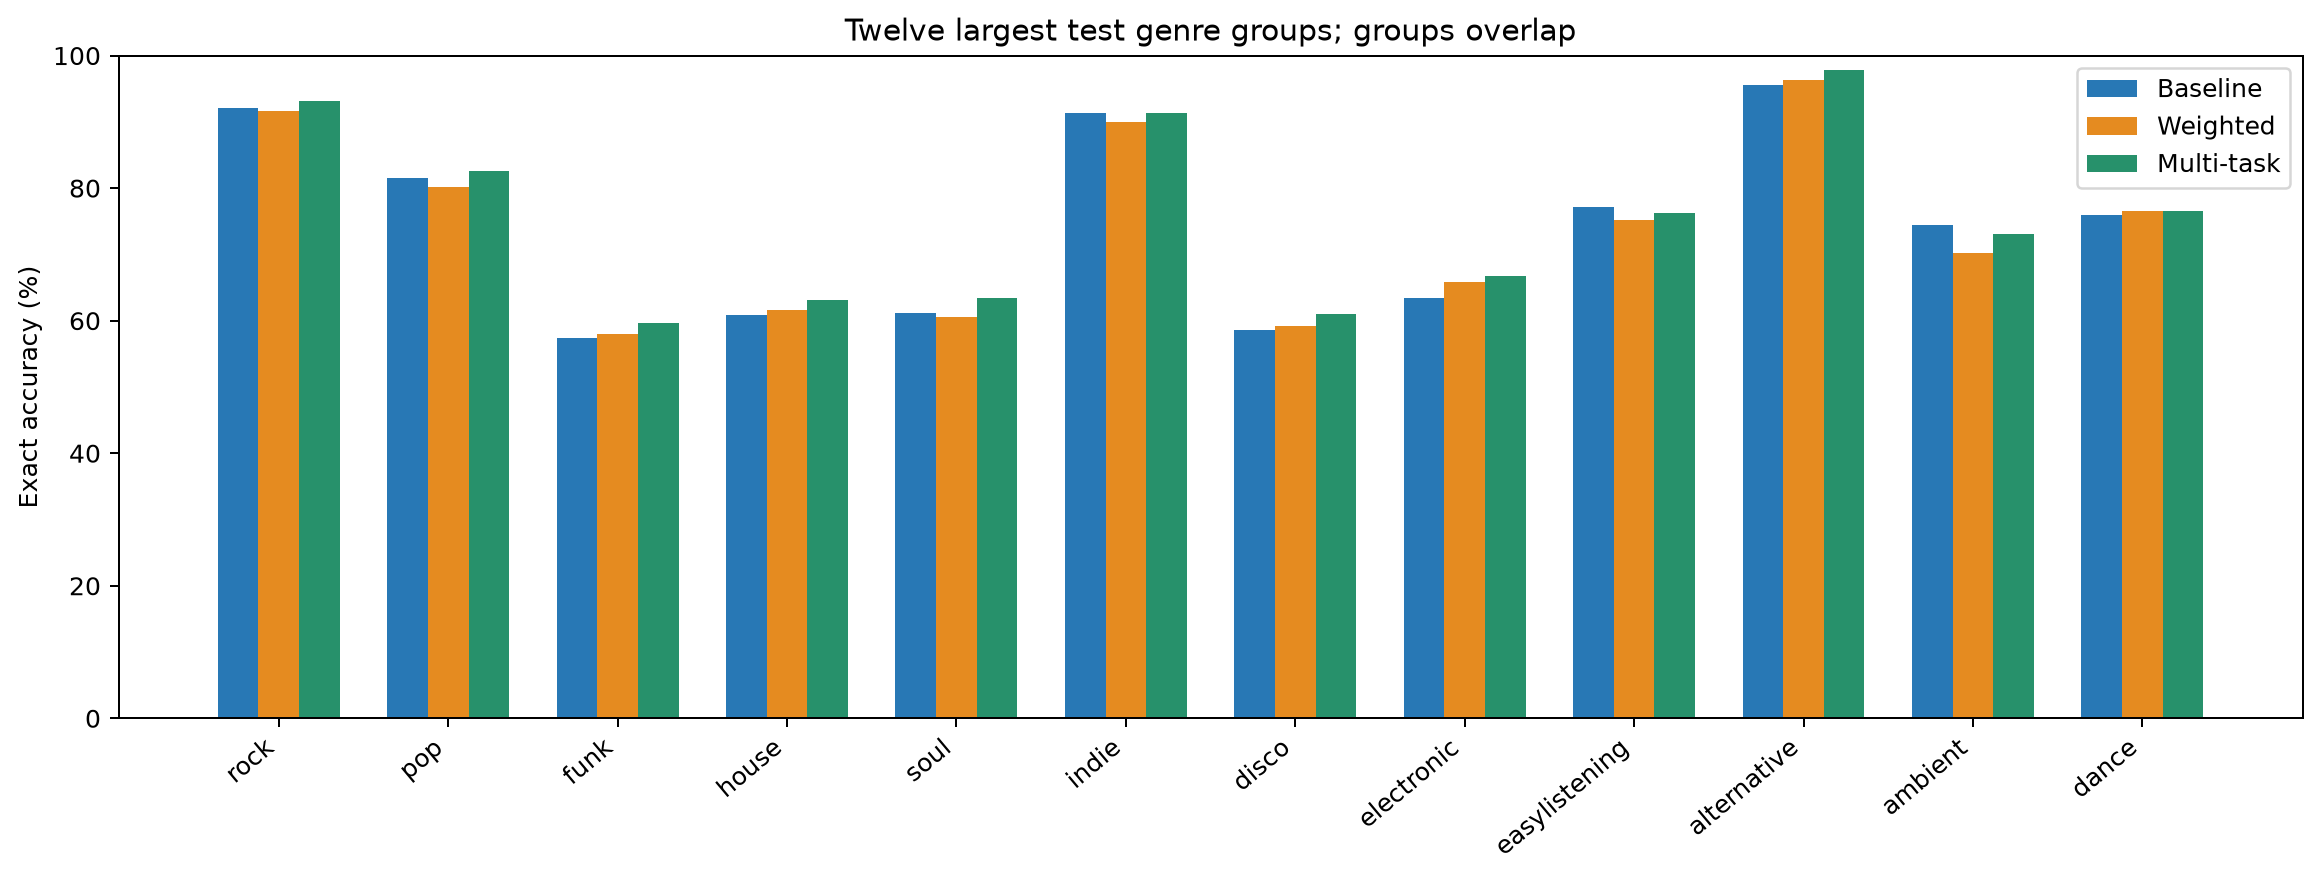

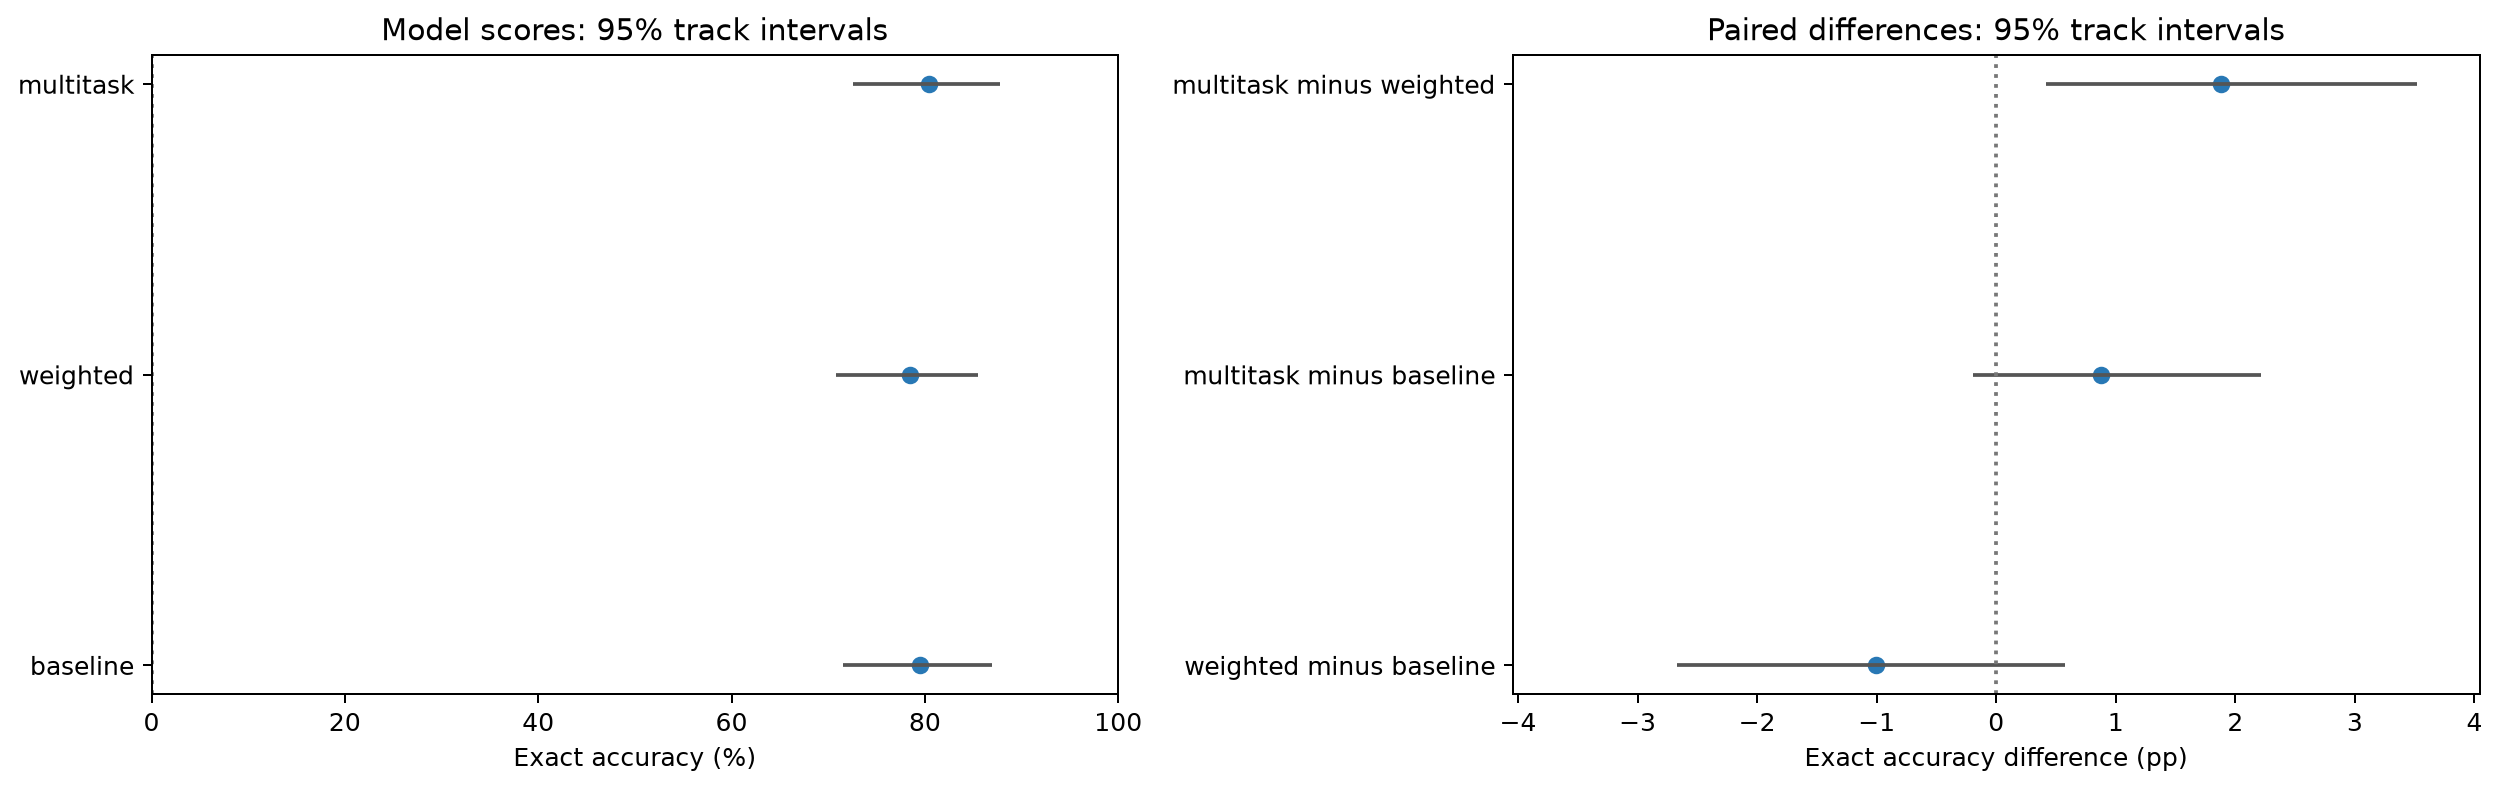

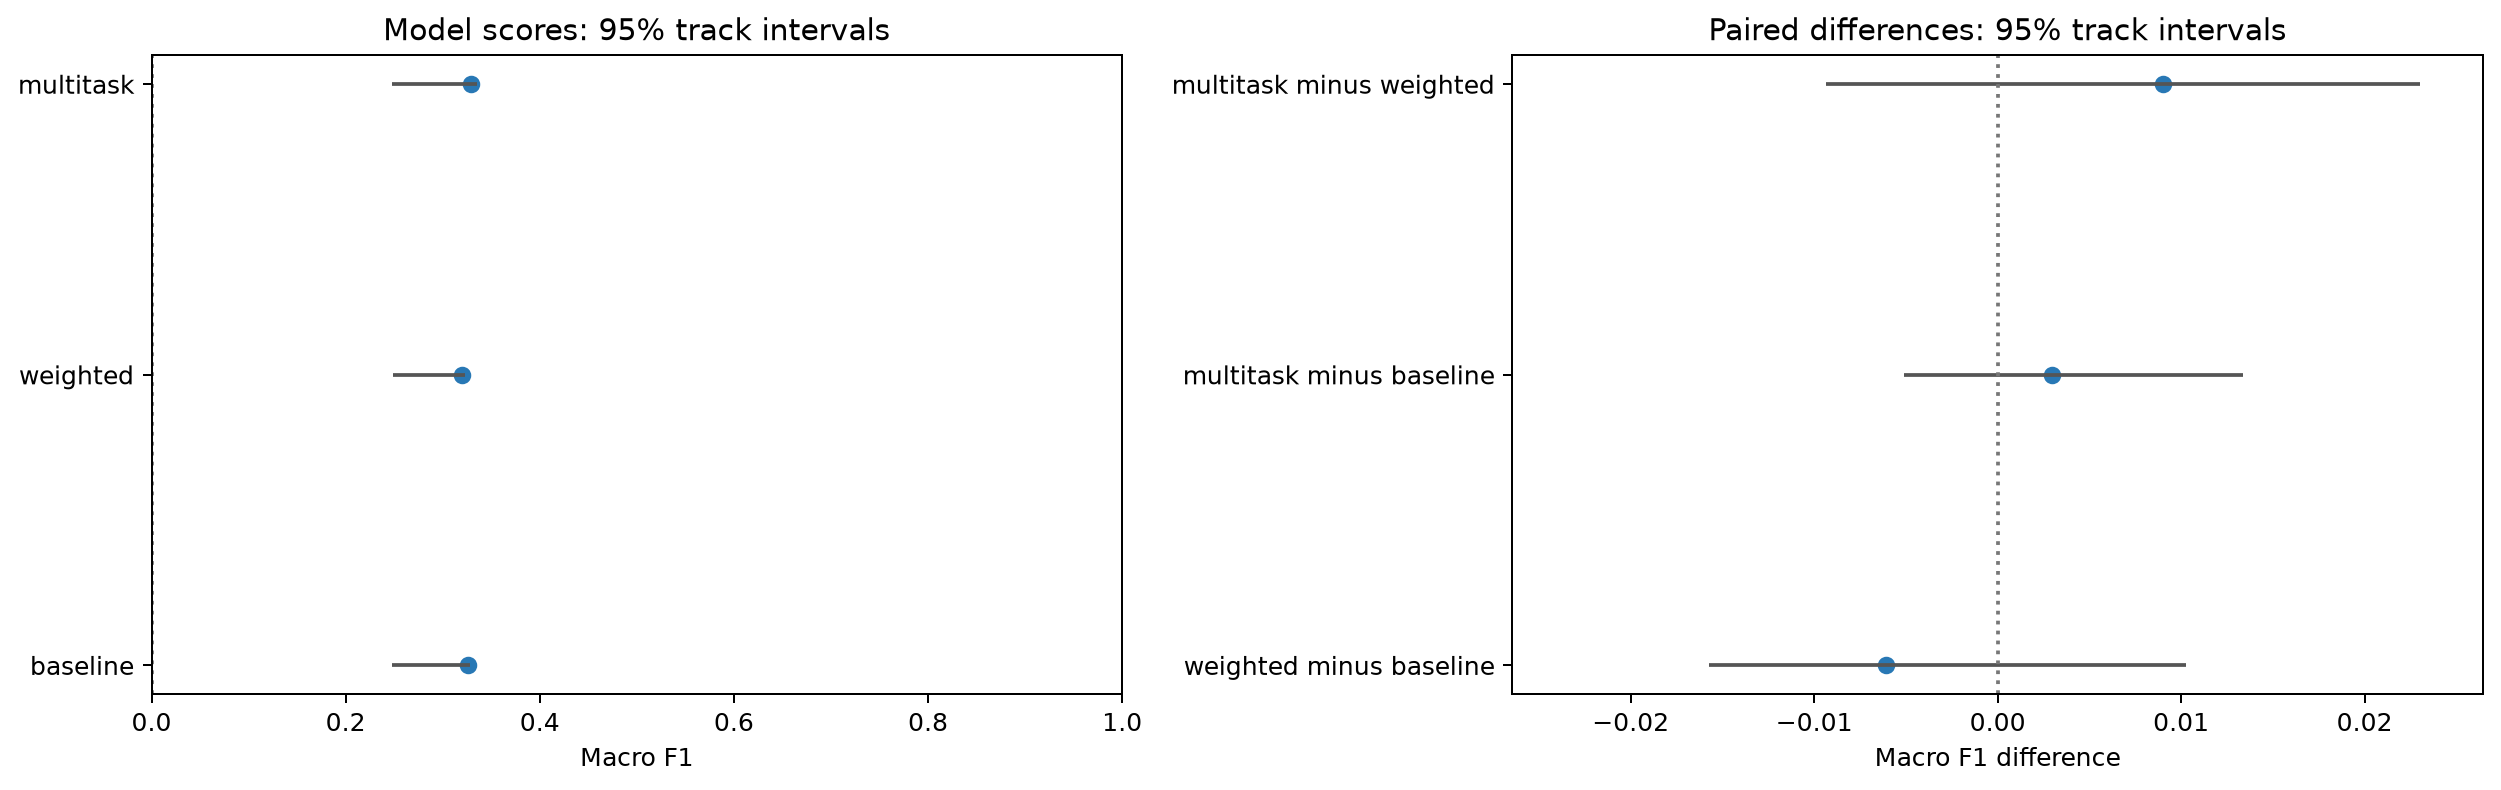

**Musical proxies/reliability:** chord-tone/key consistency and overlapping genre groups describe limited observable behavior. They do not establish listening quality or causal genre benefits. Paired intervals and single-seed limitations must accompany any numerical model ranking.

In [15]:
show_figures(['melody_compatibility','harmonic_compatibility','genre_accuracy_heatmap','genre_accuracy_bars','bootstrap_accuracy','bootstrap_macro_f1'])
display(Markdown('**Musical proxies/reliability:** chord-tone/key consistency and overlapping genre groups describe limited observable behavior. They do not establish listening quality or causal genre benefits. Paired intervals and single-seed limitations must accompany any numerical model ranking.'))

In [16]:
comparison=finalize(study)
display(comparison)
display(study.winners)
display(Markdown((OUT/'evaluation_summary.md').read_text(encoding='utf-8')))
print('Integrity verification:',read_json(OUT/'verification.json'))
print('All outputs:',OUT.relative_to(ROOT))

Verifying protected existing artifacts...


,valid_targets,exact_correct,accuracy,macro_f1,weighted_f1,macro_classes,macro_policy,macro_precision,macro_recall,weighted_precision,weighted_recall,micro_f1,model,cross_entropy,top1_accuracy,...,trainable_parameters,checkpoint_bytes,mean_batch_latency_ms,median_batch_latency_ms,p95_batch_latency_ms,valid_beats_per_second,peak_process_rss_bytes,best_epoch,completed_epochs,recorded_train_validation_seconds,maj_exact_accuracy,min_exact_accuracy,maj7_exact_accuracy,min7_exact_accuracy,7_exact_accuracy
0,14077,11192,0.795056,0.325978,0.734995,104,"Positive test-reference support, excluding reserved PAD/UNK; supervised N included.",0.313338,0.353829,0.709120,0.795056,0.795056,baseline,0.855225,0.795056,...,349074,1425714,14.576610,14.4322,17.62946,31152.427365,304205824,1,4,250.572081,0.969246,0.904563,0.0,0.209756,0.956923
1,14077,11050,0.784968,0.319876,0.736672,104,"Positive test-reference support, excluding reserved PAD/UNK; supervised N included.",0.318497,0.351780,0.719661,0.784968,0.784968,weighted,0.924474,0.784968,...,349074,1426875,15.733310,15.7258,19.59300,28862.126503,303673344,2,5,337.578448,0.948214,0.883044,0.0,0.257317,0.916923
2,14077,11315,0.803793,0.328914,0.746456,104,"Positive test-reference support, excluding reserved PAD/UNK; supervised N included.",0.325526,0.353681,0.721289,0.803793,0.803793,multitask,0.812550,0.803793,...,350751,1438929,15.951367,15.6498,20.07390,28467.577963,307044352,1,4,282.438169,0.971230,0.914126,0.0,0.249390,0.956923


,metric,best_models,best_value,direction
0,accuracy,[multitask],0.803793,maximize
1,macro_precision,[multitask],0.325526,maximize
2,macro_recall,[baseline],0.353829,maximize
3,macro_f1,[multitask],0.328914,maximize
4,weighted_precision,[multitask],0.721289,maximize
5,weighted_recall,[multitask],0.803793,maximize
6,weighted_f1,[multitask],0.746456,maximize
7,micro_f1,[multitask],0.803793,maximize
8,cross_entropy,[multitask],0.812550,minimize
9,top3_accuracy,[baseline],0.941749,maximize


# Comprehensive Transformer evaluation

All three best checkpoints were freshly evaluated on the same 14,077 valid beats, 990 sequences and 32 test tracks. No training, vocabulary fitting, data rebuilding, candidate filtering or quality re-ranking occurred.

| Metric | Baseline | Weighted | Multi-task |
|---|---:|---:|---:|
| accuracy | 79.51% | 78.50% | 80.38% |
| macro_f1 | 0.3260 | 0.3199 | 0.3289 |
| weighted_f1 | 0.7350 | 0.7367 | 0.7465 |
| top3_accuracy | 94.17% | 92.46% | 94.10% |
| top5_accuracy | 98.49% | 97.15% | 98.10% |
| cross_entropy | 0.8552 | 0.9245 | 0.8126 |
| maj7_exact_accuracy | 0.00% | 0.00% | 0.00% |
| min7_exact_accuracy | 20.98% | 25.73% | 24.94% |

## Main observations

Multi-task minus baseline exact accuracy: +0.874 percentage points; paired 95% track-bootstrap interval [-0.192, +2.219] points. The interval includes zero; this test population does not establish a reliable accuracy advantage.

Major-seventh results (individual exact labels, not broad major-family scores):
- Baseline: exact 0/926, top-3 52.81%, top-5 100.00%; mean reference probability 3.60%.
- Weighted: exact 0/926, top-3 49.35%, top-5 81.97%; mean reference probability 4.78%.
- Multi-task: exact 0/926, top-3 54.54%, top-5 100.00%; mean reference probability 4.25%.

Auxiliary head only: quality accuracy 83.32%, macro F1 0.5115. Maj7 quality recall 0.216%, precision 12.50%. These are not full-chord accuracies.

## Best model by metric

- accuracy: Multi-task
- macro_precision: Multi-task
- macro_recall: Baseline
- macro_f1: Multi-task
- weighted_precision: Multi-task
- weighted_recall: Multi-task
- weighted_f1: Multi-task
- micro_f1: Multi-task
- cross_entropy: Multi-task
- top3_accuracy: Baseline
- top5_accuracy: Baseline
- mean_reciprocal_rank: Multi-task
- mean_reference_probability: Multi-task
- mean_batch_latency_ms: Baseline
- valid_beats_per_second: Baseline

## Musical diagnostics and efficiency

Chord-tone membership is overlap-duration weighted, with a common eligible population across models. Key compatibility uses explicit major/natural-minor chord-tone membership. Function agreement is against basic-derived context and is not independent harmonic truth. Non-chord tones and non-diatonic chords may be musically appropriate. See musical_diagnostic_rules.json for exact rules and tables for denominators.

Genre analyses use overlapping original annotation groups. They describe reference-label prediction, not causal evidence that genre inputs improve generation or stylistic listening quality.

Inference timing is new forward-only measurement after warm-up, with the same CPU/device, threads, batch size and saved test data. Each model is measured in its own fresh worker process. Loading/transfers/CE/top-k are excluded; both multitask heads are included. Process peak memory includes libraries/model/cached data, not just activations. Historical training duration is a sum of logged epoch timers, not inferred from epoch counts.

## Limitations

- Single training seed per approach: initialization and training-run variability have not been measured.
- Only 32 test tracks; long tracks contribute more beats. Track bootstrap does not account fully for shared artist/album dependence. Macro-F1 intervals use a fixed original test class set and are sensitive to classes absent from resamples.
- Reference chords and melody/key/beat estimates are automatic pseudo-labels; basic inputs are reference-derived synthetic simplifications.
- Masked/unseen targets are excluded; N is included in objective metrics and excluded from pitch-class compatibility when no tone set is defined.
- Quality-only correctness does not imply exact root/extension/inversion correctness. Musical proxies and top-k candidates are not listening-test results.
- CPU throughput fluctuates with scheduling, thermal state and other processes. Historical training and newly measured inference durations are different measurements.

## Recommended next experiments

1. Repeat training across multiple seeds before declaring an overall winner; keep the held-out test set out of tuning decisions.
2. Audit maj7 pseudo-labels, per-track distribution and discriminating melody/context evidence. Test validation-selected context/loss ablations; the auxiliary task has not solved maj7 exact prediction.
3. Evaluate independently generated basic progressions and use expert listening or a defined compatibility study for musical suitability.
4. If candidate suggestions are the application, evaluate validation-designed top-k selection and user choices separately from raw top-1 classification.

All numerical tables, raw top-five predictions and uncertainty samples are saved with this run. Zero-support/unmeasurable entries remain unavailable rather than invented.


Integrity verification: {'status': 'complete', 'same_targets_all_models': True, 'valid_targets_per_model': 14077, 'test_tracks': 32, 'published_metrics_reproduced': True, 'all_predictions_finite': True, 'existing_artifacts_unchanged': 147, 'dataset_artifact_hashes_verified': 533, 'saved_figures': 27, 'saved_csv_tables': 43, 'no_retraining': True, 'no_reranking': True, 'paired_event_identity_sha256': '05bfbeeb1be94daee05cf4ee4c3b43e6e97372e2e2dff7024dbdeb6c9fb08cf9'}
All outputs: experiments\rahul\outputs\comprehensive_model_evaluation


## 12. Key findings and limitations

The generated summary above reports actual model rankings, major-seventh results, confidence intervals and recommended next experiments. Do not copy historical numbers into a new evaluation. If compatibility checks or published-metric reproduction fails, investigate the dataset/checkpoint/mask/candidate policy rather than silently remapping classes or suppressing discrepancies.

The experiment compares one saved checkpoint per method on an automatically labelled synthetic-refinement task. It does not test seed variability, independently generated basic chords or expert listening quality. Auxiliary quality correctness and related-chord errors are not exact chord correctness. Keep test data for reporting; choose future loss/context/ranking settings on validation data.

**Deliverables:** `model_comparison.csv/json`, `evaluation_summary.md`, `implementation_report.md/json`, `verification.json`, `protocol.json`, `tables/` (per-class, quality, ranks, examples, bootstrap, genres, errors, histories and efficiency), `figures/`, compressed prediction/confusion/bootstrap arrays and a hashed artifact inventory. All prior notebooks, checkpoints, datasets and previous evaluation outputs are protected.